# Libraries

In [1]:
!pip install -q -U ultralytics

In [2]:

%pip install -q     "pandas==2.2.3"     "requests==2.32.4"     "paddleocr>=3.3,<3.8"     "paddlepaddle>=3.3,<3.5"     "opencv-python-headless"     "rapidfuzz"     "beautifulsoup4"     "pillow"     "matplotlib"

print("✅ Installation completed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 48.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.
✅ Installation completed.


# Part 1

## Load Image and Model -> Individual Book Spines

In [3]:
import os
import glob
import shutil
from pathlib import Path

from google.colab import files

In [4]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import numpy as np

MODEL_PATH = "/content/best_v1.pt"
IMAGE_PATH = "/content/books.jpeg"

model = YOLO(MODEL_PATH, task="segment")

results = model.predict(
    source=IMAGE_PATH,
    imgsz=960,
    conf=0.25,
    retina_masks=True,
    verbose=False
)

result = results[0]

print("Model task:", model.task)
print("Boxes:", result.boxes is not None)
print("Masks:", result.masks is not None)

if result.masks is not None:
    print("Number of masks:", len(result.masks))
    print("Number of polygons:", len(result.masks.xy))

    for i, polygon in enumerate(result.masks.xy):
        print(
            f"Polygon {i}: "
            f"{polygon.shape[0]} points"
        )
else:
    print("❌ NO MASKS RETURNED")

Model task: segment
Boxes: True
Masks: True
Number of masks: 20
Number of polygons: 20
Polygon 0: 708 points
Polygon 1: 543 points
Polygon 2: 523 points
Polygon 3: 497 points
Polygon 4: 590 points
Polygon 5: 377 points
Polygon 6: 530 points
Polygon 7: 475 points
Polygon 8: 408 points
Polygon 9: 408 points
Polygon 10: 323 points
Polygon 11: 245 points
Polygon 12: 628 points
Polygon 13: 282 points
Polygon 14: 106 points
Polygon 15: 557 points
Polygon 16: 94 points
Polygon 17: 196 points
Polygon 18: 121 points
Polygon 19: 604 points


In [5]:
def show_segmentation_polygons(
    model,
    image_path,
    conf=0.25,
    imgsz=960,
    line_thickness=3
):

    results = model.predict(
        source=image_path,
        imgsz=imgsz,
        conf=conf,
        retina_masks=True,
        verbose=False
    )

    result = results[0]

    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f"Could not read image: {image_path}"
        )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    output = image.copy()

    if result.masks is None:

        print("❌ No segmentation masks detected.")

        plt.figure(figsize=(14, 10))
        plt.imshow(output)
        plt.axis("off")
        plt.show()

        return result

    polygons = result.masks.xy

    print(f"✅ Detected {len(polygons)} polygons")

    for i, polygon in enumerate(polygons):

        polygon = np.asarray(
            polygon,
            dtype=np.int32
        )

        # Draw polygon outline
        cv2.polylines(
            output,
            [polygon],
            isClosed=True,
            color=(255, 0, 0),
            thickness=line_thickness
        )

        # Add center label
        M = cv2.moments(polygon)

        if M["m00"] != 0:

            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])

            cv2.putText(
                output,
                str(i + 1),
                (cx, cy),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 0, 0),
                2,
                cv2.LINE_AA
            )

    plt.figure(figsize=(16, 10))

    plt.imshow(output)

    plt.title(
        f"{model.model.__class__.__name__} | "
        f"{len(polygons)} Segmented Book Spines"
    )

    plt.axis("off")

    plt.show()

    return result

✅ Detected 20 polygons


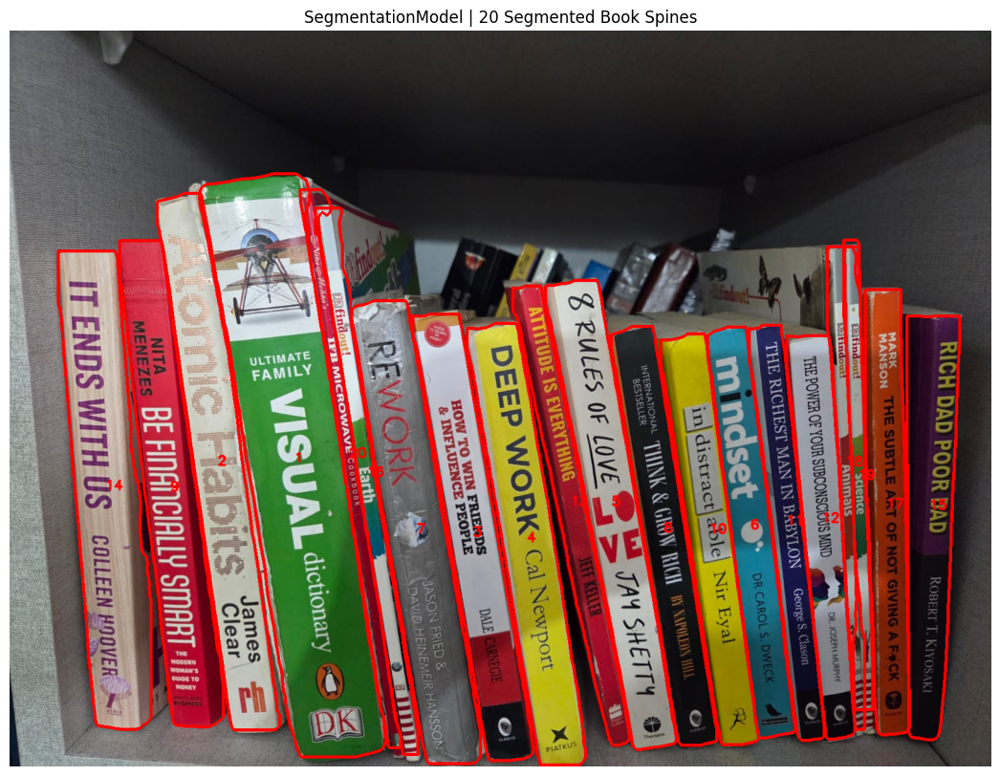

In [6]:
result = show_segmentation_polygons(
    model,
    IMAGE_PATH,
    conf=0.25,
    imgsz=960
)

In [7]:
def show_masks_and_polygons(
    model,
    image_path,
    conf=0.25,
    imgsz=960,
    alpha=0.35,
    line_thickness=3
):

    results = model.predict(
        source=image_path,
        imgsz=imgsz,
        conf=conf,
        retina_masks=True,
        verbose=False
    )

    result = results[0]

    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    output = image.copy()

    if result.masks is None:

        print("❌ No masks returned.")
        return

    masks = result.masks.data.cpu().numpy()

    polygons = result.masks.xy

    print(f"✅ Masks detected: {len(masks)}")
    print(f"✅ Polygons detected: {len(polygons)}")

    # ---------------------------------------------------------
    # CREATE FILLED MASK OVERLAY
    # ---------------------------------------------------------

    overlay = output.copy()

    for mask in masks:

        mask = cv2.resize(
            mask.astype(np.uint8),
            (output.shape[1], output.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )

        overlay[mask > 0] = (
            0,
            255,
            0
        )

    output = cv2.addWeighted(
        output,
        1 - alpha,
        overlay,
        alpha,
        0
    )

    # ---------------------------------------------------------
    # DRAW POLYGON OUTLINES
    # ---------------------------------------------------------

    for i, polygon in enumerate(polygons):

        polygon = np.asarray(
            polygon,
            dtype=np.int32
        )

        cv2.polylines(
            output,
            [polygon],
            True,
            (255, 0, 0),
            line_thickness
        )

        M = cv2.moments(polygon)

        if M["m00"] != 0:

            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])

            cv2.putText(
                output,
                f"Book {i + 1}",
                (cx, cy),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 255, 0),
                2,
                cv2.LINE_AA
            )

    # ---------------------------------------------------------
    # DISPLAY
    # ---------------------------------------------------------

    plt.figure(figsize=(18, 12))

    plt.imshow(output)

    plt.title(
        f"Segmentation: {len(polygons)} Book Spines"
    )

    plt.axis("off")

    plt.show()

✅ Masks detected: 20
✅ Polygons detected: 20


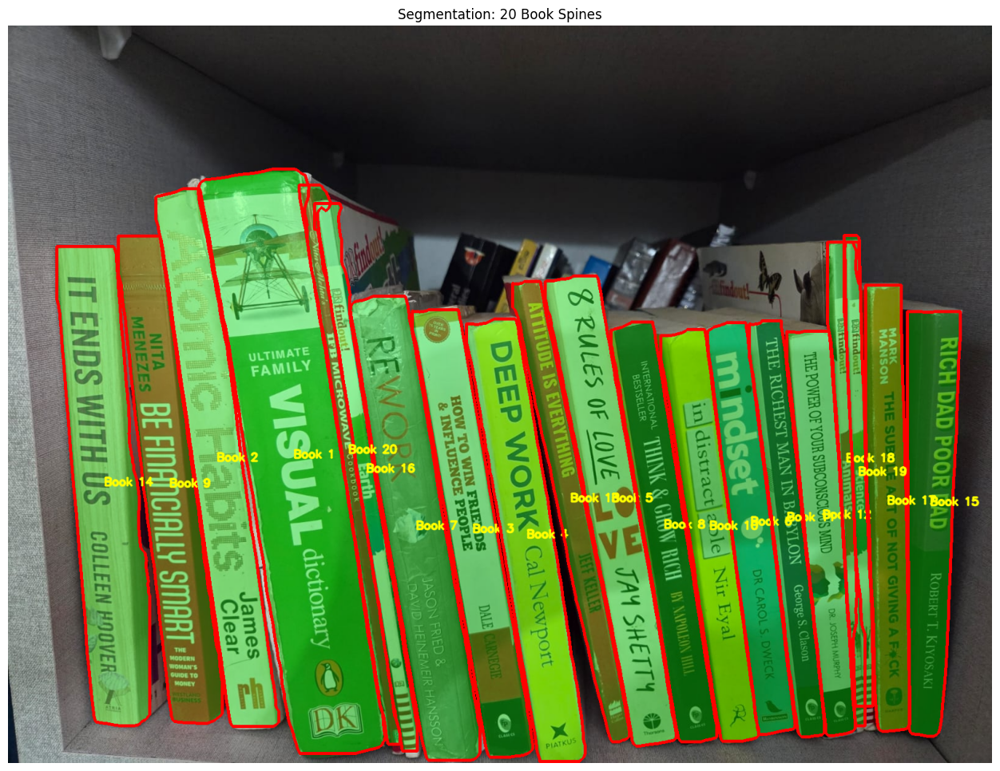

In [8]:
show_masks_and_polygons(
    model,
    IMAGE_PATH,
    conf=0.25,
    imgsz=960
)

In [9]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt


def crop_and_display_books(
    model,
    image_path,
    conf=0.25,
    imgsz=960,
    padding=5,
    cols=4,
    save_crops=True,
    output_dir="/content/book_spine_crops"
):

    # ---------------------------------------------------------
    # 1. RUN SEGMENTATION
    # ---------------------------------------------------------

    results = model.predict(
        source=image_path,
        imgsz=imgsz,
        conf=conf,
        retina_masks=True,
        verbose=False
    )

    result = results[0]

    # ---------------------------------------------------------
    # 2. READ IMAGE
    # ---------------------------------------------------------

    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f"Could not read image: {image_path}"
        )

    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # ---------------------------------------------------------
    # 3. CHECK MASKS
    # ---------------------------------------------------------

    if result.masks is None:

        print("❌ No book spines detected.")
        return []

    polygons = result.masks.xy

    print(f"✅ Total book spines detected: {len(polygons)}")

    # ---------------------------------------------------------
    # 4. CREATE OUTPUT DIRECTORY
    # ---------------------------------------------------------

    if save_crops:

        os.makedirs(
            output_dir,
            exist_ok=True
        )

    # ---------------------------------------------------------
    # 5. SORT BOOKS LEFT → RIGHT
    # ---------------------------------------------------------

    book_data = []

    for i, polygon in enumerate(polygons):

        polygon = np.asarray(
            polygon,
            dtype=np.int32
        )

        x_min = np.min(polygon[:, 0])
        y_min = np.min(polygon[:, 1])
        x_max = np.max(polygon[:, 0])
        y_max = np.max(polygon[:, 1])

        center_x = (x_min + x_max) / 2

        book_data.append({
            "polygon": polygon,
            "x_min": x_min,
            "y_min": y_min,
            "x_max": x_max,
            "y_max": y_max,
            "center_x": center_x
        })

    book_data.sort(
        key=lambda x: x["center_x"]
    )

    # ---------------------------------------------------------
    # 6. CREATE INDIVIDUAL CROPS
    # ---------------------------------------------------------

    cropped_books = []

    img_h, img_w = image.shape[:2]

    for book_index, book in enumerate(book_data, 1):

        polygon = book["polygon"]

        # Bounding box
        x_min = max(
            0,
            int(book["x_min"]) - padding
        )

        y_min = max(
            0,
            int(book["y_min"]) - padding
        )

        x_max = min(
            img_w,
            int(book["x_max"]) + padding
        )

        y_max = min(
            img_h,
            int(book["y_max"]) + padding
        )

        # -----------------------------------------------------
        # Create mask for this polygon
        # -----------------------------------------------------

        full_mask = np.zeros(
            (img_h, img_w),
            dtype=np.uint8
        )

        cv2.fillPoly(
            full_mask,
            [polygon],
            255
        )

        # Crop mask and image
        crop_mask = full_mask[
            y_min:y_max,
            x_min:x_max
        ]

        crop = image_rgb[
            y_min:y_max,
            x_min:x_max
        ]

        # -----------------------------------------------------
        # Apply mask
        # -----------------------------------------------------

        masked_crop = cv2.bitwise_and(
            crop,
            crop,
            mask=crop_mask
        )

        cropped_books.append(
            masked_crop
        )

        # -----------------------------------------------------
        # Save crop
        # -----------------------------------------------------

        if save_crops:

            save_path = os.path.join(
                output_dir,
                f"book_{book_index:02d}.jpg"
            )

            cv2.imwrite(
                save_path,
                cv2.cvtColor(
                    masked_crop,
                    cv2.COLOR_RGB2BGR
                )
            )

    # ---------------------------------------------------------
    # 7. DISPLAY ALL CROPS
    # ---------------------------------------------------------

    n_books = len(cropped_books)

    rows = int(
        np.ceil(n_books / cols)
    )

    plt.figure(
        figsize=(4 * cols, 6 * rows)
    )

    for i, crop in enumerate(
        cropped_books,
        1
    ):

        ax = plt.subplot(
            rows,
            cols,
            i
        )

        ax.imshow(crop)

        ax.set_title(
            f"Book {i}",
            fontsize=12,
            fontweight="bold"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # 8. SUMMARY
    # ---------------------------------------------------------

    print(
        f"\n✅ {n_books} individual book spine crops created."
    )

    if save_crops:

        print(
            f"📁 Saved to: {output_dir}"
        )

    return cropped_books

✅ Total book spines detected: 20


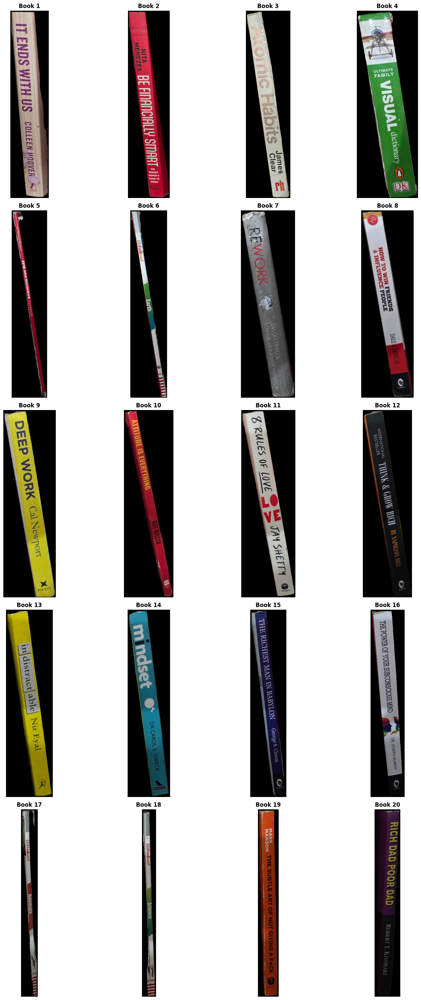


✅ 20 individual book spine crops created.
📁 Saved to: /content/book_spine_crops


In [10]:
cropped_books = crop_and_display_books(
    model=model,
    image_path=IMAGE_PATH,
    conf=0.25,
    imgsz=960,
    padding=5,
    cols=4,
    save_crops=True
)

#### Source: Book_Spine_OCR_GPT_V2.ipynb

In [ ]:
# ============================================================
# CELL 2 — IMPORTS + GLOBAL CONFIGURATION
# ============================================================

import os
import re
import json
import time
import math
import shutil
import zipfile
import warnings
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import cv2
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from PIL import Image
from rapidfuzz import fuzz
from IPython.display import display, HTML

import paddle
from paddleocr import PaddleOCR

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# INPUT / OUTPUT
# ------------------------------------------------------------

LOCAL_CROPS_DIR = Path("/content/book_spine_crops")
DRIVE_CROPS_DIR = Path("/content/drive/MyDrive/book_spine_crops")
UPLOADED_CROPS_DIR = Path("/content/book_spine_crops_uploaded")

OUTPUT_DIR = Path("/content/book_ocr_output")
RECTIFIED_DIR = OUTPUT_DIR / "rectified_spines"
DEBUG_DIR = OUTPUT_DIR / "ocr_debug"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RECTIFIED_DIR.mkdir(parents=True, exist_ok=True)
DEBUG_DIR.mkdir(parents=True, exist_ok=True)

OCR_JSON_PATH = OUTPUT_DIR / "ocr_results.json"
OCR_CSV_PATH = OUTPUT_DIR / "ocr_book_text.csv"
FINAL_CSV_PATH = OUTPUT_DIR / "book_metadata.csv"
FINAL_JSON_PATH = OUTPUT_DIR / "book_metadata.json"
CACHE_PATH = OUTPUT_DIR / "google_books_cache.json"
ZIP_PATH = Path("/content/book_spine_ocr_complete_results.zip")

# ------------------------------------------------------------
# OCR SETTINGS
# ------------------------------------------------------------

OCR_VERSION = "PP-OCRv6"
OCR_LANG = "en"

# Because geometry is rectified before OCR, text-line orientation
# classification is not required for the main OCR pass.
USE_TEXTLINE_ORIENTATION = False

# After geometric rectification the spine is horizontal.
# We only test forward and reverse reading directions.
OCR_DIRECTIONS = [0, 180]

# Upscale dimensions for OCR.
TARGET_LONG_SIDE = 1800
MAX_LONG_SIDE = 2600
PADDING = 45

# Minimum connected component area relative to image area.
MIN_COMPONENT_AREA_RATIO = 0.01

# Text acceptance.
MIN_LINE_SCORE = 0.20

# ------------------------------------------------------------
# GOOGLE BOOKS
# ------------------------------------------------------------

GOOGLE_BOOKS_API_URL = "https://www.googleapis.com/books/v1/volumes"
GOOGLE_BOOKS_API_KEY = '...' #Place ur Google Books API key here
REQUEST_TIMEOUT = 30
MAX_RESULTS_PER_QUERY = 10
GOOGLE_REQUEST_DELAY = 0.35
MAX_RETRIES = 4

GOOGLE_MATCH_LOW_THRESHOLD = 50.0
GOOGLE_MATCH_MEDIUM_THRESHOLD = 70.0

# ------------------------------------------------------------
# RUNTIME
# ------------------------------------------------------------

HAS_CUDA = bool(paddle.is_compiled_with_cuda())
if HAS_CUDA:
    try:
        DEVICE = f"gpu:{paddle.device.cuda.device_count() and 0}"
    except Exception:
        DEVICE = "gpu:0"
else:
    DEVICE = "cpu"

print("Paddle version:", paddle.__version__)
print("Paddle CUDA available:", HAS_CUDA)
print("OCR device:", DEVICE)
print("Output directory:", OUTPUT_DIR)


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Paddle version: 3.3.1
Paddle CUDA available: False
OCR device: cpu
Output directory: /content/book_ocr_output


In [12]:
# ============================================================
# CELL 3 — LOCATE / UPLOAD THE INDIVIDUAL SPINE CROPS
# ============================================================

from google.colab import drive, files as colab_files

def mount_drive_safely():
    try:
        drive.mount("/content/drive", force_remount=False)
        print("✅ Google Drive mounted.")
        return True
    except Exception as e:
        print("⚠️ Google Drive mount skipped:", e)
        return False

def find_image_files(folder: Path) -> List[Path]:
    if not folder.exists():
        return []
    allowed = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
    return sorted(
        [p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in allowed],
        key=lambda p: p.name.lower()
    )

mount_drive_safely()

# Search order:
# 1. Drive
# 2. local /content/book_spine_crops
# 3. upload ZIP
crop_files = find_image_files(DRIVE_CROPS_DIR)

if not crop_files:
    crop_files = find_image_files(LOCAL_CROPS_DIR)

if not crop_files:
    print("No existing crop folder found.")
    print("Please upload a ZIP containing your individual book-spine crops.")
    uploaded = colab_files.upload()

    if not uploaded:
        raise RuntimeError("No ZIP/images were uploaded.")

    selected_files = list(uploaded.keys())

    # If user uploaded a ZIP, extract it.
    zip_candidates = [f for f in selected_files if f.lower().endswith(".zip")]

    if zip_candidates:
        zip_name = zip_candidates[0]
        if UPLOADED_CROPS_DIR.exists():
            shutil.rmtree(UPLOADED_CROPS_DIR)
        UPLOADED_CROPS_DIR.mkdir(parents=True, exist_ok=True)

        with zipfile.ZipFile(zip_name, "r") as zf:
            zf.extractall(UPLOADED_CROPS_DIR)

        crop_files = find_image_files(UPLOADED_CROPS_DIR)
    else:
        # Individual image upload fallback.
        UPLOADED_CROPS_DIR.mkdir(parents=True, exist_ok=True)
        for f in selected_files:
            src = Path(f)
            if src.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}:
                shutil.copy2(src, UPLOADED_CROPS_DIR / src.name)

        crop_files = find_image_files(UPLOADED_CROPS_DIR)

if not crop_files:
    raise RuntimeError("No supported image files were found.")

print(f"✅ Found {len(crop_files)} individual book-spine crops.")
for p in crop_files[:20]:
    print(" ", p)


⚠️ Google Drive mount skipped: Error: credential propagation was unsuccessful
✅ Found 20 individual book-spine crops.
  /content/book_spine_crops/book_01.jpg
  /content/book_spine_crops/book_02.jpg
  /content/book_spine_crops/book_03.jpg
  /content/book_spine_crops/book_04.jpg
  /content/book_spine_crops/book_05.jpg
  /content/book_spine_crops/book_06.jpg
  /content/book_spine_crops/book_07.jpg
  /content/book_spine_crops/book_08.jpg
  /content/book_spine_crops/book_09.jpg
  /content/book_spine_crops/book_10.jpg
  /content/book_spine_crops/book_11.jpg
  /content/book_spine_crops/book_12.jpg
  /content/book_spine_crops/book_13.jpg
  /content/book_spine_crops/book_14.jpg
  /content/book_spine_crops/book_15.jpg
  /content/book_spine_crops/book_16.jpg
  /content/book_spine_crops/book_17.jpg
  /content/book_spine_crops/book_18.jpg
  /content/book_spine_crops/book_19.jpg
  /content/book_spine_crops/book_20.jpg


In [13]:
# ============================================================
# CELL 4 — INPUT IMAGE QUALITY / DIMENSION CHECK
# ============================================================

rows = []

for p in crop_files:
    img = cv2.imread(str(p))
    if img is None:
        rows.append({
            "file": p.name,
            "width": None,
            "height": None,
            "aspect_ratio": None,
            "readable": False,
        })
        continue

    h, w = img.shape[:2]
    rows.append({
        "file": p.name,
        "width": w,
        "height": h,
        "aspect_ratio": round(w / max(h, 1), 3),
        "readable": True,
    })

input_df = pd.DataFrame(rows)
display(input_df)

print(f"Readable crops: {int(input_df['readable'].sum())}/{len(input_df)}")


,file,width,height,aspect_ratio,readable
0,book_01.jpg,161,790,0.204,True
1,book_02.jpg,179,803,0.223,True
2,book_03.jpg,210,885,0.237,True
3,book_04.jpg,313,961,0.326,True
4,book_05.jpg,174,920,0.189,True
5,book_06.jpg,177,901,0.196,True
6,book_07.jpg,221,765,0.289,True
7,book_08.jpg,206,738,0.279,True
8,book_09.jpg,203,728,0.279,True
9,book_10.jpg,200,759,0.264,True


Readable crops: 20/20


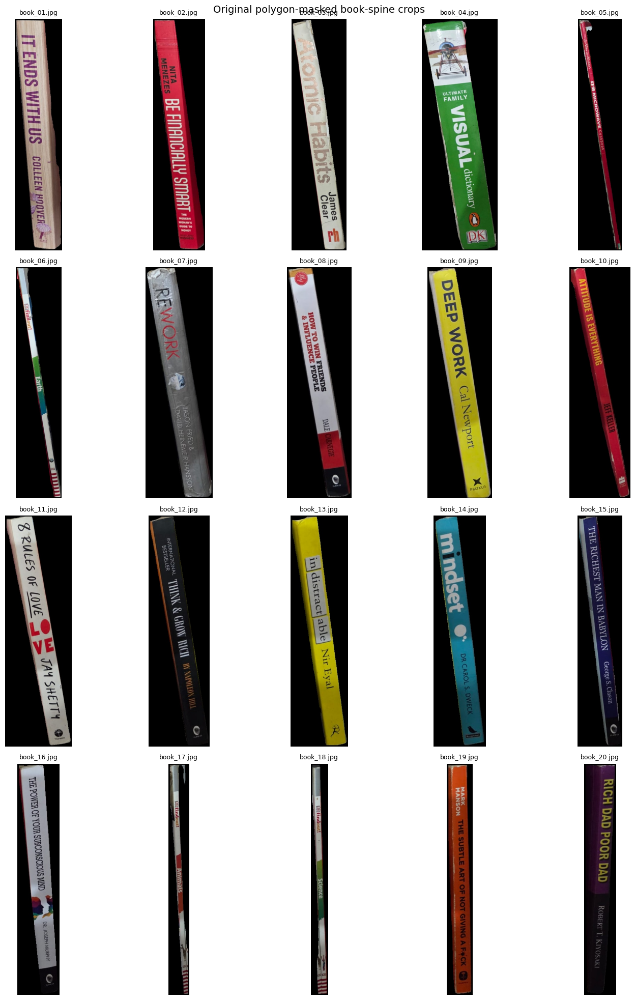

In [14]:
# ============================================================
# CELL 5 — DISPLAY ORIGINAL CROPS
# ============================================================

def show_image_grid(paths: List[Path], cols: int = 5, figsize_per_cell=(3.0, 5.0), title="Images"):
    if not paths:
        return

    n = len(paths)
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(figsize_per_cell[0] * cols, figsize_per_cell[1] * rows))

    axes = np.array(axes).reshape(-1)

    for ax, path in zip(axes, paths):
        img = cv2.imread(str(path))
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)
        ax.set_title(path.name, fontsize=9)
        ax.axis("off")

    for ax in axes[len(paths):]:
        ax.axis("off")

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_image_grid(crop_files, cols=5, title="Original polygon-masked book-spine crops")


## Geometric rectification

Because the uploaded crops have black pixels outside the segmented spine, we can recover the foreground shape.

The rectifier:

- finds the largest non-black foreground component
- reconstructs its polygonal contour
- computes a stable oriented rectangle
- warps the spine into a horizontal rectangle
- adds a clean white border
- upscales small spines

This is deliberately done **before OCR**.

That addresses the key problem in the previous notebook: many of your spines were diagonal, while the previous OCR stage only tried 0°, 90°, 180°, and 270° on the unrectified images.


In [15]:
# ============================================================
# CELL 6 — FOREGROUND MASK + POLYGON / ORIENTED RECTIFICATION
# ============================================================

def largest_foreground_contour(image_bgr: np.ndarray) -> Tuple[Optional[np.ndarray], np.ndarray]:
    """
    Reconstruct the segmented foreground from the black background.
    Returns (largest_contour, cleaned_mask).
    """
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    # Black background is approximately zero in the supplied masked crops.
    mask = (gray > 8).astype(np.uint8) * 255

    # Close gaps in the segmented spine boundary.
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)

    # Remove tiny speckles.
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)

    if num_labels <= 1:
        return None, mask

    areas = stats[1:, cv2.CC_STAT_AREA]
    largest_idx = 1 + int(np.argmax(areas))
    largest_area = int(stats[largest_idx, cv2.CC_STAT_AREA])

    image_area = image_bgr.shape[0] * image_bgr.shape[1]
    if largest_area < MIN_COMPONENT_AREA_RATIO * image_area:
        return None, mask

    cleaned = np.zeros_like(mask)
    cleaned[labels == largest_idx] = 255

    contours, _ = cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None, cleaned

    contour = max(contours, key=cv2.contourArea)
    return contour, cleaned


def order_quad_points(points: np.ndarray) -> np.ndarray:
    """
    Orders four points as:
    top-left, top-right, bottom-right, bottom-left
    """
    pts = np.asarray(points, dtype=np.float32)

    s = pts.sum(axis=1)
    d = np.diff(pts, axis=1).reshape(-1)

    top_left = pts[np.argmin(s)]
    bottom_right = pts[np.argmax(s)]
    top_right = pts[np.argmin(d)]
    bottom_left = pts[np.argmax(d)]

    return np.array([top_left, top_right, bottom_right, bottom_left], dtype=np.float32)


def rectify_with_oriented_rectangle(image_bgr: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray, float]:
    """
    Rectify the foreground spine using its oriented minimum-area rectangle.

    Returns:
        rectified image,
        foreground mask,
        box points,
        angle of long axis before rectification
    """
    contour, mask = largest_foreground_contour(image_bgr)

    if contour is None:
        raise ValueError("Could not find a foreground spine component.")

    rect = cv2.minAreaRect(contour)
    box = cv2.boxPoints(rect).astype(np.float32)

    # Determine the two side lengths.
    edges = []
    for i in range(4):
        p1 = box[i]
        p2 = box[(i + 1) % 4]
        length = float(np.linalg.norm(p2 - p1))
        edges.append((length, p1, p2))

    # The long edge becomes the horizontal axis.
    long_edge = max(edges, key=lambda x: x[0])
    short_edge = min(edges, key=lambda x: x[0])

    long_len = long_edge[0]
    short_len = max(short_edge[0], 1.0)

    # Keep enough resolution for thin text.
    out_w = max(256, int(round(long_len)))
    out_h = max(64, int(round(short_len)))

    # Recover a robust 4-point rectangle and then force width > height.
    ordered = order_quad_points(box)

    top_left, top_right, bottom_right, bottom_left = ordered

    width_top = np.linalg.norm(top_right - top_left)
    width_bottom = np.linalg.norm(bottom_right - bottom_left)
    height_right = np.linalg.norm(bottom_right - top_right)
    height_left = np.linalg.norm(bottom_left - top_left)

    quad_w = max(width_top, width_bottom)
    quad_h = max(height_right, height_left)

    if quad_h > quad_w:
        # Swap interpretation so the long dimension becomes width.
        ordered = np.array(
            [bottom_left, top_left, top_right, bottom_right],
            dtype=np.float32
        )
        out_w, out_h = int(round(quad_h)), int(round(quad_w))

    out_w = max(out_w, 256)
    out_h = max(out_h, 64)

    dst = np.array([
        [0, 0],
        [out_w - 1, 0],
        [out_w - 1, out_h - 1],
        [0, out_h - 1],
    ], dtype=np.float32)

    M = cv2.getPerspectiveTransform(ordered.astype(np.float32), dst)
    rectified = cv2.warpPerspective(
        image_bgr,
        M,
        (out_w, out_h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0),
    )

    # Measure long-axis angle from the selected long edge.
    dx = long_edge[2][0] - long_edge[1][0]
    dy = long_edge[2][1] - long_edge[1][1]
    angle = math.degrees(math.atan2(dy, dx))

    # Normalize to approximately [-90, 90).
    while angle >= 90:
        angle -= 180
    while angle < -90:
        angle += 180

    return rectified, mask, box, angle


def crop_to_foreground_and_pad(rectified_bgr: np.ndarray) -> np.ndarray:
    """
    Remove black margins, create a clean white OCR canvas,
    and upscale while keeping aspect ratio.
    """
    gray = cv2.cvtColor(rectified_bgr, cv2.COLOR_BGR2GRAY)
    fg = (gray > 8).astype(np.uint8) * 255

    coords = cv2.findNonZero(fg)

    if coords is not None:
        x, y, w, h = cv2.boundingRect(coords)
        rectified_bgr = rectified_bgr[y:y+h, x:x+w]

    # White background helps the detector when the source mask has black outside areas.
    white_bg = np.full_like(rectified_bgr, 255)
    gray2 = cv2.cvtColor(rectified_bgr, cv2.COLOR_BGR2GRAY)
    fg2 = (gray2 > 8).astype(np.uint8) * 255

    # Feather-free compositing keeps the original pixels inside the spine.
    clean = white_bg.copy()
    clean[fg2 > 0] = rectified_bgr[fg2 > 0]

    h, w = clean.shape[:2]
    scale = TARGET_LONG_SIDE / max(h, w)
    scale = max(scale, 1.0)

    new_w = min(MAX_LONG_SIDE, max(256, int(round(w * scale))))
    new_h = max(64, int(round(h * (new_w / max(w, 1)))))

    clean = cv2.resize(clean, (new_w, new_h), interpolation=cv2.INTER_CUBIC)

    clean = cv2.copyMakeBorder(
        clean,
        PADDING, PADDING, PADDING, PADDING,
        borderType=cv2.BORDER_CONSTANT,
        value=(255, 255, 255),
    )

    return clean


def rectify_spine(image_path: Path) -> Dict[str, Any]:
    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(f"Could not read: {image_path}")

    # --------------------------------------------------------
    # 1. Geometric rectification
    # --------------------------------------------------------
    rectified, mask, box, angle = rectify_with_oriented_rectangle(image)

    # --------------------------------------------------------
    # 2. Crop foreground + padding + upscale
    # --------------------------------------------------------
    clean = crop_to_foreground_and_pad(rectified)

    # --------------------------------------------------------
    # 3. IMPORTANT:
    #    Correct the 180° orientation ambiguity produced by
    #    minAreaRect / perspective transformation.
    # --------------------------------------------------------
    clean = cv2.rotate(
        clean,
        cv2.ROTATE_180
    )

    return {
        "image": clean,
        "mask": mask,
        "box": box,
        "angle": angle,
    }


In [16]:
# ============================================================
# CELL 7 — RECTIFY ALL SPINES + SAVE THEM
# ============================================================

rectification_records = []

for idx, path in enumerate(crop_files, start=1):
    try:
        result = rectify_spine(path)
        rectified = result["image"]

        out_path = RECTIFIED_DIR / path.name
        cv2.imwrite(str(out_path), rectified)

        rectification_records.append({
            "book_index": idx,
            "source_file": str(path),
            "rectified_file": str(out_path),
            "source_name": path.name,
            "source_angle_deg": round(float(result["angle"]), 2),
            "rectified_width": rectified.shape[1],
            "rectified_height": rectified.shape[0],
            "status": "ok",
        })

        print(
            f"[{idx}/{len(crop_files)}] {path.name} | "
            f"estimated angle={result['angle']:.1f}° | "
            f"rectified={rectified.shape[1]}x{rectified.shape[0]}"
        )

    except Exception as e:
        rectification_records.append({
            "book_index": idx,
            "source_file": str(path),
            "rectified_file": "",
            "source_name": path.name,
            "source_angle_deg": None,
            "rectified_width": None,
            "rectified_height": None,
            "status": f"error: {e}",
        })
        print(f"[{idx}/{len(crop_files)}] {path.name} | ❌ {e}")

rectification_df = pd.DataFrame(rectification_records)
display(rectification_df)


[1/20] book_01.jpg | estimated angle=84.6° | rectified=1890x343
[2/20] book_02.jpg | estimated angle=82.8° | rectified=1890x293
[3/20] book_03.jpg | estimated angle=81.3° | rectified=1890x270
[4/20] book_04.jpg | estimated angle=80.2° | rectified=1890x430
[5/20] book_05.jpg | estimated angle=80.6° | rectified=1890x214
[6/20] book_06.jpg | estimated angle=81.3° | rectified=1890x207
[7/20] book_07.jpg | estimated angle=79.9° | rectified=1890x328
[8/20] book_08.jpg | estimated angle=79.8° | rectified=1890x291
[9/20] book_09.jpg | estimated angle=80.0° | rectified=1890x311
[10/20] book_10.jpg | estimated angle=78.3° | rectified=1890x228
[11/20] book_11.jpg | estimated angle=79.4° | rectified=1890x304
[12/20] book_12.jpg | estimated angle=80.6° | rectified=1890x285
[13/20] book_13.jpg | estimated angle=82.0° | rectified=1890x300
[14/20] book_14.jpg | estimated angle=82.1° | rectified=1890x285
[15/20] book_15.jpg | estimated angle=83.4° | rectified=1890x251
[16/20] book_16.jpg | estimated an

,book_index,source_file,rectified_file,source_name,source_angle_deg,rectified_width,rectified_height,status
0,1,/content/book_spine_crops/book_01.jpg,/content/book_ocr_output/rectified_spines/book...,book_01.jpg,84.62,1890,343,ok
1,2,/content/book_spine_crops/book_02.jpg,/content/book_ocr_output/rectified_spines/book...,book_02.jpg,82.80,1890,293,ok
2,3,/content/book_spine_crops/book_03.jpg,/content/book_ocr_output/rectified_spines/book...,book_03.jpg,81.29,1890,270,ok
3,4,/content/book_spine_crops/book_04.jpg,/content/book_ocr_output/rectified_spines/book...,book_04.jpg,80.16,1890,430,ok
4,5,/content/book_spine_crops/book_05.jpg,/content/book_ocr_output/rectified_spines/book...,book_05.jpg,80.62,1890,214,ok
5,6,/content/book_spine_crops/book_06.jpg,/content/book_ocr_output/rectified_spines/book...,book_06.jpg,81.31,1890,207,ok
6,7,/content/book_spine_crops/book_07.jpg,/content/book_ocr_output/rectified_spines/book...,book_07.jpg,79.88,1890,328,ok
7,8,/content/book_spine_crops/book_08.jpg,/content/book_ocr_output/rectified_spines/book...,book_08.jpg,79.85,1890,291,ok
8,9,/content/book_spine_crops/book_09.jpg,/content/book_ocr_output/rectified_spines/book...,book_09.jpg,80.05,1890,311,ok
9,10,/content/book_spine_crops/book_10.jpg,/content/book_ocr_output/rectified_spines/book...,book_10.jpg,78.27,1890,228,ok


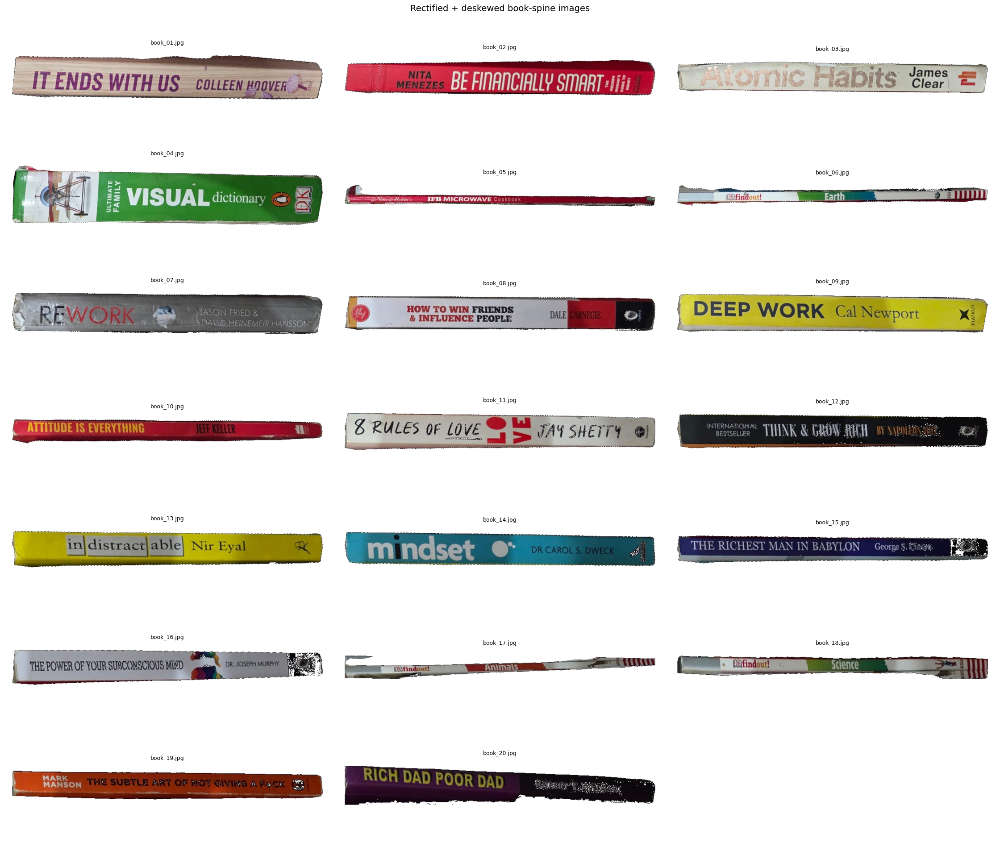

In [17]:
# ============================================================
# CELL 8 — VISUAL CHECK OF RECTIFIED SPINES
# ============================================================

rectified_paths = [
    Path(p) for p in rectification_df.loc[
        rectification_df["status"].eq("ok"), "rectified_file"
    ].tolist()
]

show_image_grid(
    rectified_paths,
    cols=3,
    figsize_per_cell=(7.5, 2.8),
    title="Rectified + deskewed book-spine images"
)


# Part 2

## Individual BookSpines -> List of Book Queries

In [18]:

# ============================================================
# PHASE 1 / STEP 1
# Environment check
# ============================================================

import sys
import subprocess
import importlib.util
from importlib import metadata

def package_version(name):
    try:
        return metadata.version(name)
    except Exception:
        return "not installed"

# Only install EasyOCR when it is actually missing.
if importlib.util.find_spec("easyocr") is None:
    print("EasyOCR not found. Installing EasyOCR 1.7.2...")
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "easyocr==1.7.2"
    ])

print("Python       :", sys.version)
print("EasyOCR      :", package_version("easyocr"))
print("PyTorch      :", package_version("torch"))
print("TorchVision  :", package_version("torchvision"))
print("OpenCV       :", package_version("opencv-python-headless"))
print("NumPy        :", package_version("numpy"))
print("Pandas       :", package_version("pandas"))
print("Pillow       :", package_version("pillow"))
print("scikit-learn :", package_version("scikit-learn"))

print("\nRunning pip check...")
check = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True
)

if check.stdout.strip():
    print(check.stdout.strip())
else:
    print("No pip dependency conflicts reported.")

if check.stderr.strip():
    print(check.stderr.strip())


Python       : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
EasyOCR      : 1.7.2
PyTorch      : 2.11.0+cu130
TorchVision  : 0.26.0+cu130
OpenCV       : 5.0.0.93
NumPy        : 2.1.3
Pandas       : 2.2.3
Pillow       : 11.3.0
scikit-learn : 1.6.1

Running pip check...
ipython 7.34.0 requires jedi, which is not installed.
google-colab 1.0.0 has requirement google-auth==2.49.0, but you have google-auth 2.62.0.


In [19]:

# ============================================================
# PHASE 1 / STEP 2
# Imports
# ============================================================

import gc
import re
import json
import math
from pathlib import Path
from difflib import SequenceMatcher

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

import torch
import easyocr

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


PyTorch : 2.11.0+cu130
CUDA    : True
GPU     : Tesla T4


In [20]:

# ============================================================
# PHASE 2 / STEP 3
# Paths and configuration
# ============================================================

INPUT_DIR = Path("/content/book_ocr_output/rectified_spines")

OUTPUT_DIR = Path("/content/BookSpine_OCR_Final_Output")
ANNOTATED_DIR = OUTPUT_DIR / "annotated"
TEXT_CROPS_DIR = OUTPUT_DIR / "text_crops"
NORMALIZED_DIR = OUTPUT_DIR / "normalized_spines"

for d in [
    OUTPUT_DIR,
    ANNOTATED_DIR,
    TEXT_CROPS_DIR,
    NORMALIZED_DIR,
]:
    d.mkdir(parents=True, exist_ok=True)

extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp",
    ".JPG", ".JPEG", ".PNG", ".BMP", ".WEBP"
}

image_files = sorted(
    p for p in INPUT_DIR.iterdir()
    if p.is_file() and p.suffix in extensions
)

if not image_files:
    raise FileNotFoundError(
        f"No images found in {INPUT_DIR}. "
        "Put individual book-spine images there."
    )

print(f"Found {len(image_files)} spine images.")
for p in image_files:
    print(" -", p.name)


Found 20 spine images.
 - book_01.jpg
 - book_02.jpg
 - book_03.jpg
 - book_04.jpg
 - book_05.jpg
 - book_06.jpg
 - book_07.jpg
 - book_08.jpg
 - book_09.jpg
 - book_10.jpg
 - book_11.jpg
 - book_12.jpg
 - book_13.jpg
 - book_14.jpg
 - book_15.jpg
 - book_16.jpg
 - book_17.jpg
 - book_18.jpg
 - book_19.jpg
 - book_20.jpg


In [21]:

# ============================================================
# PHASE 3 / STEP 4
# EasyOCR
# ============================================================

USE_GPU = torch.cuda.is_available()

reader = easyocr.Reader(
    ["en"],
    gpu=USE_GPU,
    verbose=True
)

print("EasyOCR ready.")


EasyOCR ready.


In [22]:

# ============================================================
# PHASE 4 / STEP 5
# Image normalization
# ============================================================

MAX_LONG_SIDE = 4200
TARGET_HEIGHT = 480

def read_image(path):
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)

    if image is None:
        raise ValueError(f"Could not read image: {path}")

    # Handle RGBA images.
    if image.ndim == 3 and image.shape[2] == 4:
        bgr = image[:, :, :3]
        alpha = image[:, :, 3:4].astype(np.float32) / 255.0
        white = np.full_like(bgr, 255)
        image = (
            bgr.astype(np.float32) * alpha
            + white.astype(np.float32) * (1 - alpha)
        ).astype(np.uint8)

    elif image.ndim == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    return image

def normalize_spine(image):
    h, w = image.shape[:2]

    # Scale small images upward so thin letters have more pixels.
    scale_up = (
        TARGET_HEIGHT / h
        if h < TARGET_HEIGHT
        else 1.0
    )

    # Never exceed maximum long side.
    scale_down = (
        MAX_LONG_SIDE / max(h * scale_up, w * scale_up)
        if max(h * scale_up, w * scale_up) > MAX_LONG_SIDE
        else 1.0
    )

    scale = scale_up * scale_down

    if abs(scale - 1.0) < 0.01:
        return image.copy()

    interpolation = (
        cv2.INTER_CUBIC
        if scale > 1
        else cv2.INTER_AREA
    )

    return cv2.resize(
        image,
        None,
        fx=scale,
        fy=scale,
        interpolation=interpolation
    )

def save_normalized_spine(image, path):
    out = NORMALIZED_DIR / f"{Path(path).stem}_normalized.jpg"
    cv2.imwrite(str(out), image)
    return out


In [23]:

# ============================================================
# PHASE 4 / STEP 6
# Safe deskew
# ============================================================

def estimate_foreground_angle(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Detect strong edges.
    edges = cv2.Canny(gray, 50, 150)

    # Hough line estimate.
    lines = cv2.HoughLinesP(
        edges,
        1,
        np.pi / 180,
        threshold=max(30, image.shape[1] // 20),
        minLineLength=max(50, image.shape[1] // 10),
        maxLineGap=20
    )

    if lines is None:
        return 0.0

    angles = []

    for line in lines[:, 0]:
        x1, y1, x2, y2 = line

        dx = x2 - x1
        dy = y2 - y1

        if abs(dx) < 1:
            continue

        angle = math.degrees(math.atan2(dy, dx))

        # Only near-horizontal lines are useful here.
        if -15 <= angle <= 15:
            angles.append(angle)

    if not angles:
        return 0.0

    return float(np.median(angles))

def deskew_image(image, max_angle=10.0):
    angle = estimate_foreground_angle(image)

    if abs(angle) < 0.5 or abs(angle) > max_angle:
        return image.copy(), 0.0

    h, w = image.shape[:2]
    center = (w / 2, h / 2)

    matrix = cv2.getRotationMatrix2D(
        center,
        angle,
        1.0
    )

    rotated = cv2.warpAffine(
        image,
        matrix,
        (w, h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(255, 255, 255)
    )

    return rotated, angle


In [24]:

# ============================================================
# PHASE 5 / STEP 7
# Text detection
# ============================================================

ALLOWED_CHARS = (
    "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    "abcdefghijklmnopqrstuvwxyz"
    "0123456789"
    ".,!?&'’:-/$*()"
)

DETECT_CONFIG = {
    "text_threshold": 0.40,
    "low_text": 0.20,
    "link_threshold": 0.20,
    "min_size": 6,
    "canvas_size": 3200,
    "mag_ratio": 1.0,
    "slope_ths": 0.15,
    "ycenter_ths": 0.35,
    "height_ths": 0.35,
    "width_ths": 0.50,
    "add_margin": 0.05,
    "contrast_ths": 0.05,
    "adjust_contrast": 0.50,
    "filter_ths": 0.003,
    "decoder": "beamsearch",
    "beamWidth": 5,
    "batch_size": 1,
    "paragraph": False,
    "allowlist": ALLOWED_CHARS,
}

FALLBACK_DETECT_CONFIG = {
    **DETECT_CONFIG,
    "text_threshold": 0.30,
    "low_text": 0.12,
    "link_threshold": 0.15,
    "height_ths": 0.28,
    "width_ths": 0.45,
}

def run_easyocr_detection(image, config):
    rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    kwargs = dict(config)

    return reader.readtext(
        rgb,
        detail=1,
        **kwargs
    )

def detections_to_regions(detections):
    regions = []

    for raw_id, det in enumerate(detections):

        if len(det) != 3:
            continue

        polygon, text, confidence = det

        text = clean_ocr_text(text)
        confidence = float(confidence)

        if not valid_ocr_text(text):
            continue

        polygon = np.asarray(
            polygon,
            dtype=np.float32
        )

        regions.append({
            "raw_id": raw_id,
            "polygon": polygon.tolist(),
            "box": polygon_to_bbox(polygon),
            "text": text,
            "confidence": confidence
        })

    return regions


In [25]:

# ============================================================
# PHASE 6 / STEP 8
# Cleaning and duplicate removal
# ============================================================

MIN_REGION_HEIGHT_RATIO = 0.010
MIN_ALNUM_CHARACTERS = 2

ISBN_PATTERNS = [
    re.compile(r"^(?:ISBN[:\s-]*)?97[89][0-9Xx -]{9,}$"),
    re.compile(r"^[0-9Xx -]{10,}$"),
]

NOISE_WORDS = {
    "WWW",
    "HTTP",
    "HTTPS",
    "COM",
    "ORG",
    "NET",
}

def clean_ocr_text(text):
    if text is None:
        return ""

    text = str(text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)

    return text.strip(" |[]{}").strip()

def valid_ocr_text(text):
    text = clean_ocr_text(text)

    if len(text) < 2:
        return False

    alnum_count = sum(
        c.isalnum()
        for c in text
    )

    return alnum_count >= MIN_ALNUM_CHARACTERS

def polygon_to_bbox(polygon):
    pts = np.asarray(
        polygon,
        dtype=np.float32
    )

    return [
        float(pts[:, 0].min()),
        float(pts[:, 1].min()),
        float(pts[:, 0].max()),
        float(pts[:, 1].max())
    ]

def bbox_area(box):
    x1, y1, x2, y2 = box
    return max(0.0, x2-x1) * max(0.0, y2-y1)

def bbox_iou(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    inter = (
        max(0.0, ix2-ix1)
        * max(0.0, iy2-iy1)
    )

    union = (
        bbox_area(a)
        + bbox_area(b)
        - inter
    )

    return inter / union if union else 0.0

def bbox_area_ratio(a, b):
    aa = bbox_area(a)
    ab = bbox_area(b)

    if max(aa, ab) == 0:
        return 0.0

    return min(aa, ab) / max(aa, ab)

def normalized_for_comparison(text):
    text = clean_ocr_text(text).upper()
    text = re.sub(
        r"[^A-Z0-9 ]+",
        " ",
        text
    )
    return re.sub(
        r"\s+",
        " ",
        text
    ).strip()

def text_similarity(a, b):
    a = normalized_for_comparison(a)
    b = normalized_for_comparison(b)

    if not a or not b:
        return 0.0

    return SequenceMatcher(
        None,
        a,
        b
    ).ratio()

def looks_like_isbn(text):
    compact = re.sub(
        r"[\s-]+",
        "",
        text
    )

    return any(
        p.fullmatch(compact)
        for p in ISBN_PATTERNS
    )

def looks_like_url_or_noise(text):
    upper = text.upper()

    if any(
        token in upper
        for token in NOISE_WORDS
    ):
        return True

    if re.search(
        r"(https?://|www\.)",
        text,
        flags=re.IGNORECASE
    ):
        return True

    return False

def filter_regions(regions, image_shape):
    h_img, w_img = image_shape[:2]

    filtered = []

    for region in regions:
        text = clean_ocr_text(region["text"])

        height = (
            region["box"][3]
            - region["box"][1]
        )

        height_ratio = (
            height / max(1, h_img)
        )

        # Very tiny boxes are usually logos/noise.
        # Keep somewhat larger small text because author lines
        # can legitimately be small.
        if (
            height_ratio < MIN_REGION_HEIGHT_RATIO
            and region["confidence"] < 0.70
        ):
            continue

        if len(text) == 1:
            # Keep only strong one-character text.
            if region["confidence"] < 0.88:
                continue

        if looks_like_isbn(text):
            continue

        if looks_like_url_or_noise(text):
            continue

        region["height_ratio"] = float(height_ratio)
        filtered.append(region)

    return filtered

def deduplicate_regions(regions):
    # Highest confidence first.
    regions = sorted(
        regions,
        key=lambda r: (
            r["confidence"],
            r.get("height_ratio", 0.0)
        ),
        reverse=True
    )

    kept = []

    for candidate in regions:
        duplicate = False

        for existing in kept:

            iou = bbox_iou(
                candidate["box"],
                existing["box"]
            )

            area_ratio = bbox_area_ratio(
                candidate["box"],
                existing["box"]
            )

            text_sim = text_similarity(
                candidate["text"],
                existing["text"]
            )

            # Same region with high geometry overlap.
            if (
                iou >= 0.55
                and area_ratio >= 0.55
            ):
                duplicate = True
                break

            # Same text repeated in almost the same location.
            if (
                text_sim >= 0.90
                and iou >= 0.35
            ):
                duplicate = True
                break

        if not duplicate:
            kept.append(candidate)

    return kept


In [26]:

# ============================================================
# PHASE 6 / STEP 9
# Adaptive detection
# ============================================================

def adaptive_detect(image):
    primary_raw = run_easyocr_detection(
        image,
        DETECT_CONFIG
    )

    primary = detections_to_regions(
        primary_raw
    )

    primary = filter_regions(
        primary,
        image.shape
    )

    # Trigger fallback only when primary is clearly weak.
    primary_total_chars = sum(
        len(r["text"])
        for r in primary
    )

    should_fallback = (
        len(primary) == 0
        or (
            len(primary) <= 1
            and primary_total_chars < 8
        )
    )

    if not should_fallback:
        return deduplicate_regions(primary), "primary"

    fallback_raw = run_easyocr_detection(
        image,
        FALLBACK_DETECT_CONFIG
    )

    fallback = detections_to_regions(
        fallback_raw
    )

    fallback = filter_regions(
        fallback,
        image.shape
    )

    combined = deduplicate_regions(
        primary + fallback
    )

    return combined, "primary+fallback"


In [27]:

# ============================================================
# PHASE 7 / STEP 10
# Polygon perspective crop
# ============================================================

TEXT_CROP_MIN_HEIGHT = 48
TEXT_CROP_MAX_HEIGHT = 180

def order_quad_points(points):
    pts = np.asarray(
        points,
        dtype=np.float32
    )

    if pts.shape != (4, 2):
        return None

    s = pts.sum(axis=1)
    d = np.diff(
        pts,
        axis=1
    ).ravel()

    rect = np.zeros(
        (4, 2),
        dtype=np.float32
    )

    rect[0] = pts[np.argmin(s)]  # TL
    rect[2] = pts[np.argmax(s)]  # BR
    rect[1] = pts[np.argmin(d)]  # TR
    rect[3] = pts[np.argmax(d)]  # BL

    return rect

def perspective_text_crop(
    image,
    polygon,
    padding=8
):
    pts = np.asarray(
        polygon,
        dtype=np.float32
    )

    if pts.shape != (4, 2):
        x1,y1,x2,y2 = polygon_to_bbox(pts)

        x1 = max(
            0,
            int(round(x1)) - padding
        )
        y1 = max(
            0,
            int(round(y1)) - padding
        )
        x2 = min(
            image.shape[1],
            int(round(x2)) + padding
        )
        y2 = min(
            image.shape[0],
            int(round(y2)) + padding
        )

        return (
            image[y1:y2, x1:x2].copy()
            if x2 > x1 and y2 > y1
            else None
        )

    rect = order_quad_points(pts)

    if rect is None:
        return None

    tl, tr, br, bl = rect

    def dist(a, b):
        return float(
            np.linalg.norm(a-b)
        )

    width = max(
        dist(tl, tr),
        dist(bl, br)
    )

    height = max(
        dist(tl, bl),
        dist(tr, br)
    )

    width = int(round(width))
    height = int(round(height))

    if width < 3 or height < 3:
        return None

    dst_w = width + 2 * padding
    dst_h = height + 2 * padding

    dst = np.array([
        [padding, padding],
        [dst_w-padding-1, padding],
        [dst_w-padding-1, dst_h-padding-1],
        [padding, dst_h-padding-1]
    ], dtype=np.float32)

    matrix = cv2.getPerspectiveTransform(
        rect,
        dst
    )

    crop = cv2.warpPerspective(
        image,
        matrix,
        (dst_w, dst_h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(255,255,255)
    )

    return crop if crop.size else None

def resize_text_crop_for_recognition(crop):
    h, w = crop.shape[:2]

    if h < TEXT_CROP_MIN_HEIGHT:
        scale = TEXT_CROP_MIN_HEIGHT / max(1, h)

    elif h > TEXT_CROP_MAX_HEIGHT:
        scale = TEXT_CROP_MAX_HEIGHT / h

    else:
        scale = 1.0

    if abs(scale-1.0) < 0.01:
        return crop

    return cv2.resize(
        crop,
        None,
        fx=scale,
        fy=scale,
        interpolation=(
            cv2.INTER_CUBIC
            if scale > 1
            else cv2.INTER_AREA
        )
    )


In [28]:

# ============================================================
# PHASE 8 / STEP 11
# Recognition variants
# ============================================================

RECOGNITION_CONFIDENCE_THRESHOLD = 0.72

def recognition_variants(crop):
    variants = [
        ("original", crop)
    ]

    gray = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2GRAY
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8,8)
    )

    enhanced = clahe.apply(gray)

    variants.append((
        "clahe",
        cv2.cvtColor(
            enhanced,
            cv2.COLOR_GRAY2BGR
        )
    ))

    _, otsu = cv2.threshold(
        enhanced,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    variants.append((
        "otsu",
        cv2.cvtColor(
            otsu,
            cv2.COLOR_GRAY2BGR
        )
    ))

    return variants

def recognize_text_crop(crop):
    results = []

    for variant_name, variant in recognition_variants(crop):

        rgb = cv2.cvtColor(
            variant,
            cv2.COLOR_BGR2RGB
        )

        try:
            detections = reader.readtext(
                rgb,
                detail=1,
                paragraph=False,

                decoder="beamsearch",
                beamWidth=5,

                allowlist=ALLOWED_CHARS,

                contrast_ths=0.05,
                adjust_contrast=0.50,
                filter_ths=0.003,

                text_threshold=0.35,
                low_text=0.15,
                link_threshold=0.15,

                canvas_size=2600,
                mag_ratio=1.15,

                batch_size=1
            )
        except Exception:
            continue

        if not detections:
            continue

        best = max(
            detections,
            key=lambda x: float(x[2])
        )

        text = clean_ocr_text(best[1])
        confidence = float(best[2])

        if valid_ocr_text(text):
            results.append({
                "variant": variant_name,
                "text": text,
                "confidence": confidence
            })

    if not results:
        return {
            "text": "",
            "confidence": 0.0,
            "variant": None,
            "agreement": 0
        }

    best = None
    best_score = -1.0
    best_agreement = 0

    for candidate in results:

        agreement = sum(
            text_similarity(
                candidate["text"],
                other["text"]
            ) >= 0.72
            for other in results
            if other is not candidate
        )

        # Confidence plus agreement.
        score = (
            candidate["confidence"]
            + 0.08 * agreement
        )

        if score > best_score:
            best_score = score
            best = candidate
            best_agreement = agreement

    return {
        "text": best["text"],
        "confidence": float(best["confidence"]),
        "variant": best["variant"],
        "agreement": int(best_agreement)
    }


In [29]:

# ============================================================
# PHASE 8 / STEP 12
# Region recognition
# ============================================================

def refine_region_recognition(
    image,
    region
):
    crop = perspective_text_crop(
        image,
        region["polygon"],
        padding=8
    )

    if crop is None:
        region["crop"] = None
        return region

    crop = resize_text_crop_for_recognition(
        crop
    )

    region["crop"] = crop

    # Keep strong detections.
    if region["confidence"] >= RECOGNITION_CONFIDENCE_THRESHOLD:
        region["recognition_variant"] = "detector_output"
        region["recognition_agreement"] = 0
        return region

    retry = recognize_text_crop(
        crop
    )

    if (
        retry["text"]
        and retry["confidence"]
        >= region["confidence"]
    ):
        region["text"] = retry["text"]
        region["confidence"] = retry["confidence"]

    region["recognition_variant"] = retry["variant"]
    region["recognition_agreement"] = retry["agreement"]

    return region


In [30]:

# ============================================================
# PHASE 9 / STEP 13
# Text-line grouping
# ============================================================

LINE_VERTICAL_OVERLAP = 0.45
LINE_HEIGHT_RATIO_MIN = 0.55
LINE_HEIGHT_RATIO_MAX = 1.80
LINE_GAP_FACTOR = 2.5

def vertical_overlap(a, b):
    inter = max(
        0.0,
        min(a[3], b[3]) - max(a[1], b[1])
    )

    denom = min(
        max(1.0, a[3]-a[1]),
        max(1.0, b[3]-b[1])
    )

    return inter / denom

def horizontal_gap(a, b):
    if a[0] <= b[0]:
        return max(0.0, b[0]-a[2])

    return max(0.0, a[0]-b[2])

def should_group_same_line(a, b):
    h1 = max(
        1.0,
        a["box"][3]-a["box"][1]
    )

    h2 = max(
        1.0,
        b["box"][3]-b["box"][1]
    )

    ratio = h1 / h2

    if not (
        LINE_HEIGHT_RATIO_MIN
        <= ratio
        <= LINE_HEIGHT_RATIO_MAX
    ):
        return False

    if vertical_overlap(
        a["box"],
        b["box"]
    ) < LINE_VERTICAL_OVERLAP:
        return False

    gap = horizontal_gap(
        a["box"],
        b["box"]
    )

    return (
        gap
        <= LINE_GAP_FACTOR * min(h1,h2)
    )

def group_text_lines(regions):
    if not regions:
        return []

    regions = sorted(
        regions,
        key=lambda r: (
            (r["box"][1]+r["box"][3])/2,
            r["box"][0]
        )
    )

    groups = []

    for region in regions:
        assigned = False

        for group in groups:

            reference = group[-1]

            if should_group_same_line(
                reference,
                region
            ):
                group.append(region)
                assigned = True
                break

        if not assigned:
            groups.append([region])

    lines = []

    for line_id, group in enumerate(groups):

        group = sorted(
            group,
            key=lambda r: r["box"][0]
        )

        text = " ".join(
            clean_ocr_text(r["text"])
            for r in group
        )

        x1 = min(
            r["box"][0]
            for r in group
        )

        y1 = min(
            r["box"][1]
            for r in group
        )

        x2 = max(
            r["box"][2]
            for r in group
        )

        y2 = max(
            r["box"][3]
            for r in group
        )

        confidence = float(
            np.mean([
                r["confidence"]
                for r in group
            ])
        )

        lines.append({
            "line_id": line_id,
            "members": group,
            "text": clean_ocr_text(text),
            "confidence": confidence,
            "box": [x1,y1,x2,y2]
        })

    return lines


In [31]:
# ============================================================
# PHASE 10 / STEP 14
# Typography features: size + stroke width + visual style
# ============================================================

def uppercase_ratio(text):
    letters = [c for c in text if c.isalpha()]
    return sum(c.isupper() for c in letters) / len(letters) if letters else 0.0


def digit_ratio(text):
    chars = [c for c in text if c.isalnum()]
    return sum(c.isdigit() for c in chars) / len(chars) if chars else 0.0


def punctuation_ratio(text):
    if not text:
        return 0.0
    return sum(
        not c.isalnum() and not c.isspace()
        for c in text
    ) / len(text)


def estimate_stroke_width(image, box):
    """Estimate relative text stroke width from a cropped OCR line."""
    x1, y1, x2, y2 = map(int, [round(v) for v in box])
    pad = 4

    x1 = max(0, x1 - pad)
    y1 = max(0, y1 - pad)
    x2 = min(image.shape[1], x2 + pad)
    y2 = min(image.shape[0], y2 + pad)

    crop = image[y1:y2, x1:x2]

    if crop.size == 0:
        return 0.0, 0.0

    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    _, binary = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    candidates = [binary, 255 - binary]
    plausible = []

    for mask in candidates:
        ratio = float(np.mean(mask > 0))
        if 0.01 <= ratio <= 0.45:
            plausible.append((abs(ratio - 0.18), mask))

    if plausible:
        selected = min(plausible, key=lambda x: x[0])[1]
    else:
        selected = min(
            candidates,
            key=lambda m: float(np.mean(m > 0))
        )

    fg = (selected > 0).astype(np.uint8) * 255

    kernel = np.ones((2, 2), np.uint8)
    fg = cv2.morphologyEx(
        fg,
        cv2.MORPH_OPEN,
        kernel
    )

    if not np.any(fg > 0):
        return 0.0, 0.0

    dist = cv2.distanceTransform(
        fg,
        cv2.DIST_L2,
        3
    )

    values = dist[fg > 0]

    if values.size == 0:
        return 0.0, 0.0

    stroke_px = float(
        np.percentile(values, 75) * 2.0
    )

    normalized = stroke_px / max(1, crop.shape[0])

    return stroke_px, normalized


def detect_case_style(text):
    text = clean_ocr_text(text)
    letters = [c for c in text if c.isalpha()]

    if not letters:
        return "NUMERIC_OR_SYMBOL"

    upper = sum(c.isupper() for c in letters) / len(letters)
    lower = sum(c.islower() for c in letters) / len(letters)

    words = [w for w in text.split() if w]

    title_case_words = sum(
        bool(re.match(r"^[A-Z][a-z]", w))
        for w in words
    )

    if upper >= 0.85:
        return "ALL_CAPS"
    if lower >= 0.85:
        return "LOWER_CASE"
    if words and title_case_words / len(words) >= 0.60:
        return "TITLE_CASE"

    return "MIXED_CASE"


def typography_features(line, image_shape, image):
    h_img, w_img = image_shape[:2]
    x1, y1, x2, y2 = line["box"]

    width = max(1.0, x2 - x1)
    height = max(1.0, y2 - y1)
    text = clean_ocr_text(line["text"])

    stroke_px, stroke_norm = estimate_stroke_width(
        image,
        line["box"]
    )

    return {
        "line_id": line["line_id"],
        "text": text,
        "confidence": float(line["confidence"]),
        "x1": float(x1),
        "y1": float(y1),
        "x2": float(x2),
        "y2": float(y2),
        "width": float(width),
        "height": float(height),
        "normalized_height": height / max(1.0, h_img),
        "normalized_width": width / max(1.0, w_img),
        "normalized_area": width * height / max(1.0, h_img * w_img),
        "aspect_ratio": width / height,
        "center_x": ((x1 + x2) / 2) / max(1.0, w_img),
        "center_y": ((y1 + y2) / 2) / max(1.0, h_img),
        "word_count": len(text.split()),
        "char_count": len(text),
        "uppercase_ratio": uppercase_ratio(text),
        "digit_ratio": digit_ratio(text),
        "punctuation_ratio": punctuation_ratio(text),
        "stroke_width_px": stroke_px,
        "normalized_stroke_width": stroke_norm,
        "visual_style": detect_case_style(text),
        "line": line,
    }


def assign_size_classes(rows):
    if not rows:
        return rows

    heights = np.array([
        r["normalized_height"]
        for r in rows
    ], dtype=float)

    if len(rows) == 1:
        classes = ["LARGE"]
    elif len(rows) == 2:
        order = np.argsort(heights)
        classes = [None] * len(rows)
        classes[order[0]] = "SMALL"
        classes[order[1]] = "LARGE"
    else:
        q33, q66 = np.quantile(
            heights,
            [0.33, 0.66]
        )
        classes = [
            "SMALL" if h <= q33
            else "MEDIUM" if h <= q66
            else "LARGE"
            for h in heights
        ]

    for row, cls in zip(rows, classes):
        row["size_class"] = cls

    return rows


In [32]:
# ============================================================
# PHASE 10 / STEP 15
# Typography weight classification
# ============================================================

def assign_weight_classes(rows):
    if not rows:
        return rows

    widths = np.array([
        r.get("normalized_stroke_width", 0.0)
        for r in rows
    ], dtype=float)

    valid = widths[widths > 0]

    if valid.size == 0:
        classes = ["MEDIUM"] * len(rows)
    elif len(rows) == 1:
        classes = ["MEDIUM"]
    elif len(rows) == 2:
        order = np.argsort(widths)
        classes = [None] * len(rows)
        classes[order[0]] = "LIGHT"
        classes[order[1]] = "BOLD"
    else:
        q33, q66 = np.quantile(valid,[0.33,0.66])
        classes = [
            "LIGHT" if w <= q33
            else "MEDIUM" if w <= q66
            else "BOLD"
            for w in widths
        ]

    for row, cls in zip(rows, classes):
        row["weight_class"] = cls

    return rows


In [33]:

# ============================================================
# PHASE 11 / STEP 16
# Typography grouping across horizontal + vertical lines
# ============================================================

# Separator used by the Google Books query stage.
GROUP_SEPARATOR = ", "
LINE_SEPARATOR = " "

# Continuous similarity thresholds.
# They are deliberately separate from the displayed size/weight
# class labels.
SIZE_RATIO_MIN = 0.72
WEIGHT_RATIO_MIN = 0.58

# OCR / geometry tolerance.
STYLE_CASE_MATCH = True
HORIZONTAL_START_DIFF_MAX = 0.22
HORIZONTAL_CENTER_DIFF_MAX = 0.24
HORIZONTAL_OVERLAP_MIN = 0.18

# Vertical stacking tolerance.
STACKED_LINE_MAX_GAP_FACTOR = 8.0

# Same-height / same-row tolerance.
SAME_ROW_CENTER_DIFF_FACTOR = 0.90


def ratio_similarity(a, b, eps=1e-8):
    a = float(a)
    b = float(b)

    if a <= eps or b <= eps:
        return 0.0

    return min(a, b) / max(a, b)


def row_box(row):
    """
    Return [x1, y1, x2, y2] from a real typography record.

    Real pipeline rows contain x1/y1/x2/y2.
    Some test/demo rows may contain only center/normalized geometry.
    """

    if all(k in row for k in ("x1", "y1", "x2", "y2")):
        return [
            float(row["x1"]),
            float(row["y1"]),
            float(row["x2"]),
            float(row["y2"])
        ]

    width = float(
        row.get("normalized_width", 0.0)
    )
    height = float(
        row.get("normalized_height", 0.0)
    )

    cx = float(
        row.get("center_x", 0.0)
    )
    cy = float(
        row.get("center_y", 0.0)
    )

    # These are normalized coordinates in this fallback.
    return [
        cx - width / 2.0,
        cy - height / 2.0,
        cx + width / 2.0,
        cy + height / 2.0
    ]


def horizontal_overlap_ratio(a, b):
    ax1, _, ax2, _ = row_box(a)
    bx1, _, bx2, _ = row_box(b)

    inter = max(
        0.0,
        min(ax2, bx2) - max(ax1, bx1)
    )

    denom = max(
        1e-8,
        min(
            max(0.0, ax2-ax1),
            max(0.0, bx2-bx1)
        )
    )

    return inter / denom


def horizontal_alignment_score(a, b):
    """
    Compare horizontal placement using normalized geometry.

    For real rows, x1/x2 are pixel coordinates and center_x /
    normalized_width are already normalized to the image.

    We use the normalized fields for consistent behavior.
    """

    a_width = float(
        a.get("normalized_width", 0.0)
    )
    b_width = float(
        b.get("normalized_width", 0.0)
    )

    a_center = float(
        a.get("center_x", 0.0)
    )

    b_center = float(
        b.get("center_x", 0.0)
    )

    a_left = max(
        0.0,
        a_center - a_width / 2.0
    )

    a_right = min(
        1.0,
        a_center + a_width / 2.0
    )

    b_left = max(
        0.0,
        b_center - b_width / 2.0
    )

    b_right = min(
        1.0,
        b_center + b_width / 2.0
    )

    left_diff = abs(
        a_left - b_left
    )

    center_diff = abs(
        a_center - b_center
    )

    right_diff = abs(
        a_right - b_right
    )

    overlap = horizontal_overlap_ratio(
        a,
        b
    )

    compatible = (
        left_diff <= HORIZONTAL_START_DIFF_MAX
        or center_diff <= HORIZONTAL_CENTER_DIFF_MAX
        or overlap >= HORIZONTAL_OVERLAP_MIN
    )

    return {
        "left_diff": float(left_diff),
        "center_diff": float(center_diff),
        "right_diff": float(right_diff),
        "overlap": float(overlap),
        "compatible": bool(compatible)
    }

def vertical_relation(a, b):
    """
    Determine whether two OCR lines are:
        - same row
        - vertically stacked
        - too far apart

    Works with the actual pipeline's x1/y1/x2/y2 fields.
    """

    _, ay1, _, ay2 = row_box(a)
    _, by1, _, by2 = row_box(b)

    ah = max(
        1.0,
        ay2 - ay1
    )

    bh = max(
        1.0,
        by2 - by1
    )

    a_center = (
        ay1 + ay2
    ) / 2.0

    b_center = (
        by1 + by2
    ) / 2.0

    center_distance = abs(
        a_center - b_center
    )

    # Same-row decision is scale-aware for both pixel and normalized
    # coordinate systems.
    if center_distance <= (
        SAME_ROW_CENTER_DIFF_FACTOR
        * max(ah, bh)
    ):
        return {
            "relation": "same_row",
            "gap": 0.0,
            "compatible": True
        }

    if b_center >= a_center:
        gap = max(
            0.0,
            by1 - ay2
        )
    else:
        gap = max(
            0.0,
            ay1 - by2
        )

    allowed_gap = (
        STACKED_LINE_MAX_GAP_FACTOR
        * max(ah, bh)
    )

    return {
        "relation": "stacked",
        "gap": float(gap),
        "compatible": bool(
            gap <= allowed_gap
        )
    }

def same_typography(a, b):
    """
    Continuous typography comparison.

    Size:
        normalized text-height ratio

    Weight:
        normalized estimated stroke-width ratio

    Style:
        case/style category

    A small tolerance is used because OCR boxes from two lines
    of the same font can differ slightly in height/stroke estimate.
    """

    size_sim = ratio_similarity(
        a["normalized_height"],
        b["normalized_height"]
    )

    weight_a = float(
        a.get("normalized_stroke_width", 0.0)
    )

    weight_b = float(
        b.get("normalized_stroke_width", 0.0)
    )

    weight_sim = ratio_similarity(
        weight_a,
        weight_b
    )

    if size_sim < SIZE_RATIO_MIN:
        return False

    # If one/both stroke estimates are unavailable, do not reject
    # solely on weight.
    weight_available = (
        weight_a > 0
        and weight_b > 0
    )

    if (
        weight_available
        and weight_sim < WEIGHT_RATIO_MIN
    ):
        return False

    if (
        STYLE_CASE_MATCH
        and a.get("visual_style")
        and b.get("visual_style")
        and a["visual_style"] != b["visual_style"]
    ):
        return False

    return True


def should_group_typography_lines(a, b):
    """
    Final pairwise decision.

    IMPORTANT:
    Two lines do not need vertical overlap.
    They can be above/below each other.

    The model first checks typography similarity, then checks
    whether their 2D layout is compatible.
    """

    if not same_typography(a, b):
        return False

    relation = vertical_relation(a, b)

    if not relation["compatible"]:
        return False

    alignment = horizontal_alignment_score(
        a,
        b
    )

    if relation["relation"] == "same_row":
        # Normal horizontal continuation.
        return alignment["compatible"]

    # This is the important multi-line case:
    # same typography + stacked vertically + compatible x-position.
    return alignment["compatible"]


class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
        self.rank = [0] * n

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra = self.find(a)
        rb = self.find(b)

        if ra == rb:
            return

        if self.rank[ra] < self.rank[rb]:
            self.parent[ra] = rb

        elif self.rank[ra] > self.rank[rb]:
            self.parent[rb] = ra

        else:
            self.parent[rb] = ra
            self.rank[ra] += 1


def make_group_text(members):
    """
    Reconstruct one complete phrase from one or multiple OCR lines.

    Reading order:
        top -> bottom
        then left -> right

    Fragments inside a group are joined with spaces.
    """

    ordered = sorted(
        members,
        key=lambda r: (
            r["center_y"],
            r["x1"]
        )
    )

    parts = [
        clean_ocr_text(
            r["text"]
        )
        for r in ordered
        if valid_ocr_text(r["text"])
    ]

    text = LINE_SEPARATOR.join(
        part for part in parts if part
    )

    # Basic punctuation normalization only.
    text = re.sub(
        r"\s*&\s*",
        " & ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


def group_by_typography(rows):
    """
    Group complete OCR lines by typography and 2D layout.

    This is deliberately different from the old greedy approach.

    A Union-Find graph allows:
        line 1 ↔ line 2 ↔ line 3
    to form one group when each adjacent pair matches.

    Therefore a two-line title/author is reconstructed as one
    complete phrase even when OCR detected separate up/down lines.
    """

    if not rows:
        return []

    n = len(rows)

    uf = UnionFind(n)

    pair_diagnostics = []

    for i in range(n):
        for j in range(i + 1, n):

            same = should_group_typography_lines(
                rows[i],
                rows[j]
            )

            if same:
                uf.union(i, j)

            pair_diagnostics.append({
                "a": i,
                "b": j,
                "same_typography_group": same
            })

    raw_groups = {}

    for i in range(n):
        root = uf.find(i)

        raw_groups.setdefault(
            root,
            []
        ).append(
            rows[i]
        )

    output = []

    for group_id, members in enumerate(
        raw_groups.values()
    ):

        members = sorted(
            members,
            key=lambda r: (
                r["center_y"],
                r["x1"]
            )
        )

        group_text = make_group_text(
            members
        )

        if not group_text:
            continue

        # Dominant properties for display.
        size_counts = {}
        weight_counts = {}
        style_counts = {}

        for member in members:

            size = member.get(
                "size_class",
                "UNKNOWN"
            )

            weight = member.get(
                "weight_class",
                "UNKNOWN"
            )

            style = member.get(
                "visual_style",
                "UNKNOWN"
            )

            size_counts[size] = (
                size_counts.get(size, 0)
                + 1
            )

            weight_counts[weight] = (
                weight_counts.get(weight, 0)
                + 1
            )

            style_counts[style] = (
                style_counts.get(style, 0)
                + 1
            )

        group = {
            "group_id": group_id,

            "text": group_text,

            "members": members,

            "member_line_count":
                len(members),

            "size_class":
                max(
                    size_counts,
                    key=size_counts.get
                ),

            "weight_class":
                max(
                    weight_counts,
                    key=weight_counts.get
                ),

            "visual_style":
                max(
                    style_counts,
                    key=style_counts.get
                ),

            "median_height":
                float(
                    np.median([
                        r["normalized_height"]
                        for r in members
                    ])
                ),

            "median_stroke_width":
                float(
                    np.median([
                        r["normalized_stroke_width"]
                        for r in members
                    ])
                ),

            "center_y":
                float(
                    np.mean([
                        r["center_y"]
                        for r in members
                    ])
                ),

            "x1":
                float(
                    min(
                        r["x1"]
                        for r in members
                    )
                ),

            "member_texts":
                [
                    r["text"]
                    for r in members
                ],
        }

        output.append(group)

    # Deterministic book reading order.
    output.sort(
        key=lambda g: (
            g["center_y"],
            g["x1"]
        )
    )

    # Re-index groups in visual order.
    for new_id, group in enumerate(output):

        group["group_id"] = new_id

        for member in group["members"]:
            member["typography_group"] = new_id

    return output


print(
    "Updated multi-line typography grouping is ready."
)


Updated multi-line typography grouping is ready.


In [34]:

# ============================================================
# PHASE 11 / STEP 16A
# Two-line grouping regression test
# ============================================================

def make_demo_row(
    text,
    center_x,
    center_y,
    width,
    height,
    stroke,
    style="ALL_CAPS",
    size="MEDIUM",
    weight="BOLD",
):
    return {
        "text": text,

        "normalized_height":
            height,

        "normalized_stroke_width":
            stroke,

        "center_x":
            center_x,

        "center_y":
            center_y,

        "normalized_width":
            width,

        "x1":
            center_x - width / 2,

        "x2":
            center_x + width / 2,

        "y1":
            center_y - height / 2,

        "y2":
            center_y + height / 2,

        "width":
            width,

        "height":
            height,

        "size_class":
            size,

        "weight_class":
            weight,

        "visual_style":
            style,
    }


# ------------------------------------------------------------
# BOOK 05
# ------------------------------------------------------------

book05_rows = [
    make_demo_row(
        "JASON FRIED &",
        center_x=0.50,
        center_y=0.42,
        width=0.20,
        height=0.080,
        stroke=0.018,
        size="MEDIUM",
        weight="BOLD",
        style="ALL_CAPS",
    ),

    make_demo_row(
        "DAVID HEINEMEIER HANSSON",
        center_x=0.59,
        center_y=0.55,
        width=0.35,
        height=0.076,
        stroke=0.017,
        size="MEDIUM",
        weight="BOLD",
        style="ALL_CAPS",
    ),
]

book05_groups = group_by_typography(
    book05_rows
)

print("BOOK 05 GROUPS")
for group in book05_groups:
    print(
        f"  GROUP {group['group_id']}: "
        f"{group['text']}"
    )

assert len(book05_groups) == 1, (
    "Book 05 should produce one typography group."
)

assert (
    "JASON FRIED" in book05_groups[0]["text"]
    and
    "DAVID HEINEMEIER HANSSON"
    in book05_groups[0]["text"]
), "Book 05 two-line text was not joined correctly."


# ------------------------------------------------------------
# BOOK 06
# ------------------------------------------------------------

book06_rows = [
    make_demo_row(
        "HOW TO WIN FRIENDS",
        center_x=0.25,
        center_y=0.30,
        width=0.30,
        height=0.070,
        stroke=0.014,
        size="LARGE",
        weight="BOLD",
        style="ALL_CAPS",
    ),

    make_demo_row(
        "& INFLUENCE PEOPLE",
        center_x=0.26,
        center_y=0.39,
        width=0.30,
        height=0.071,
        stroke=0.014,
        size="LARGE",
        weight="BOLD",
        style="ALL_CAPS",
    ),
]

book06_groups = group_by_typography(
    book06_rows
)

print("\nBOOK 06 GROUPS")
for group in book06_groups:
    print(
        f"  GROUP {group['group_id']}: "
        f"{group['text']}"
    )

assert len(book06_groups) == 1, (
    "Book 06 should produce one typography group."
)

assert (
    "HOW TO WIN FRIENDS" in book06_groups[0]["text"]
    and
    "INFLUENCE PEOPLE"
    in book06_groups[0]["text"]
), "Book 06 two-line text was not joined correctly."


print("\nExpected:")
print(
    "Book 05 -> JASON FRIED & "
    "DAVID HEINEMEIER HANSSON"
)
print(
    "Book 06 -> HOW TO WIN FRIENDS & "
    "INFLUENCE PEOPLE"
)

print(
    "\n2-line typography grouping regression test: PASSED"
)


BOOK 05 GROUPS
  GROUP 0: JASON FRIED & DAVID HEINEMEIER HANSSON

BOOK 06 GROUPS
  GROUP 0: HOW TO WIN FRIENDS & INFLUENCE PEOPLE

Expected:
Book 05 -> JASON FRIED & DAVID HEINEMEIER HANSSON
Book 06 -> HOW TO WIN FRIENDS & INFLUENCE PEOPLE

2-line typography grouping regression test: PASSED


In [35]:

# ============================================================
# PHASE 12 / STEP 17
# Google Books query construction
# ============================================================

def clean_query_text(text):
    text = clean_ocr_text(text)

    # Normalize ampersands and common punctuation spacing.
    text = re.sub(
        r"\s*&\s*",
        " & ",
        text
    )

    text = re.sub(
        r"\s*,\s*",
        ", ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip(" ,")


def build_google_books_query(groups):
    """
    IMPORTANT:

    Each typography group is already a complete phrase.
    We therefore join GROUPS with commas.

    Example:
        INTERNATIONAL BESTSELLER
        THINK & GROW RICH
        BY NAPOLEON HILL

    becomes:
        INTERNATIONAL BESTSELLER, THINK & GROW RICH, BY NAPOLEON HILL
    """

    ordered_groups = sorted(
        groups,
        key=lambda g: (
            g["center_y"],
            g["x1"]
        )
    )

    parts = []

    for group in ordered_groups:

        phrase = clean_query_text(
            group["text"]
        )

        if phrase:
            parts.append(
                phrase
            )

    return GROUP_SEPARATOR.join(
        parts
    )


print(
    "Google Books query builder updated."
)


Google Books query builder updated.


In [36]:
# ============================================================
# PHASE 13 / STEP 18
# Main processing
# ============================================================

results = []

for image_path in tqdm(
    image_files,
    desc="Processing book spines"
):
    try:
        image = read_image(image_path)
        image = normalize_spine(image)
        image, deskew_angle = deskew_image(image)

        save_normalized_spine(
            image,
            image_path
        )

        regions, detector_mode = adaptive_detect(
            image
        )

        refined = []

        for region in regions:
            refined.append(
                refine_region_recognition(
                    image,
                    region
                )
            )

        refined = deduplicate_regions(refined)

        lines = group_text_lines(refined)

        rows = [
            typography_features(
                line,
                image.shape,
                image
            )
            for line in lines
        ]

        rows = assign_size_classes(rows)
        rows = assign_weight_classes(rows)
        groups = group_by_typography(rows)

        query = build_google_books_query(groups)

        all_text = " | ".join(
            r["text"]
            for r in rows
            if valid_ocr_text(r["text"])
        )

        results.append({
            "file": image_path.name,
            "image_path": str(image_path),
            "google_books_query": query,
            "all_text": all_text,
            "ocr_confidence": float(
                np.mean([
                    r["confidence"]
                    for r in rows
                ]) if rows else 0.0
            ),
            "num_text_lines": len(rows),
            "num_typography_groups": len(groups),
            "grouping_method": detector_mode,
            "deskew_angle": float(deskew_angle),
            "groups": groups,
            "regions": rows,
            "image": image,
        })

    except Exception as e:
        print(
            f"FAILED: {image_path.name}: "
            f"{type(e).__name__}: {e}"
        )

        results.append({
            "file": image_path.name,
            "image_path": str(image_path),
            "google_books_query": "",
            "all_text": "",
            "ocr_confidence": 0.0,
            "num_text_lines": 0,
            "num_typography_groups": 0,
            "grouping_method": "failed",
            "deskew_angle": 0.0,
            "groups": [],
            "regions": [],
            "image": None,
        })

print(
    f"\nCompleted {len(results)} spines."
)


Processing book spines:   0%|          | 0/20 [00:00<?, ?it/s]


Completed 20 spines.


In [37]:
# ============================================================
# PHASE 14 / STEP 19
# Final API-ready table
# ============================================================

summary_rows = []

for result in results:
    summary_rows.append({
        "Book": result["file"],
        "Google Books Query": result["google_books_query"],
        "All OCR": result["all_text"],
        "OCR Confidence": round(result["ocr_confidence"],3),
        "Text Lines": result["num_text_lines"],
        "Typography Groups": result["num_typography_groups"],
        "Detector": result["grouping_method"],
        "Deskew Angle": round(result["deskew_angle"],2),
    })

final_df = pd.DataFrame(summary_rows)
display(final_df)

final_df.to_csv(
    OUTPUT_DIR / "book_spine_google_books_queries.csv",
    index=False
)


,Book,Google Books Query,All OCR,OCR Confidence,Text Lines,Typography Groups,Detector,Deskew Angle
0,book_01.jpg,ITENDSWITHUS COLLEENHOOVER,ITENDSWITHUS COLLEENHOOVER,0.884,1,1,primary,0.00
1,book_02.jpg,"NITA MENEZES, BEFIDAnCIALLYSQART Ii",NITA | BEFIDAnCIALLYSQART Ii | MENEZES,0.849,3,2,primary,0.00
2,book_03.jpg,OmicHabits'ees2,OmicHabits'ees2,0.287,1,1,primary,0.00
3,book_04.jpg,JiVISUAL: dictionary,JiVISUAL: dictionary,0.681,1,1,primary,0.00
4,book_05.jpg,"TTEMICROWAVECoo, S1chta",TTEMICROWAVECoo | S1chta,0.461,2,2,primary,0.00
5,book_06.jpg,"mw, Earth, Dnfindoutl",mw | Earth | Dnfindoutl,0.536,3,3,primary,0.00
6,book_07.jpg,"REWORK, JASONFRIED & DAVIDHEINEMEIRHANSSON",JASONFRIED& | REWORK | DAVIDHEINEMEIRHANSSON,0.966,3,2,primary,0.00
7,book_08.jpg,"HOWTOWNFRIENDS & INFLUENCEPEOPLE, DALECARNECIE",HOWTOWNFRIENDS | DALECARNECIE | &INFLUENCEPEOPLE,0.763,3,2,primary,0.00
8,book_09.jpg,DEEPWORKCalNewport,DEEPWORKCalNewport,1.000,1,1,primary,0.00
9,book_10.jpg,"ATTITUDEISEVERYTHING, EEFFKeULER, JI",ATTITUDEISEVERYTHING | EEFFKeULER | JI,0.589,3,3,primary,0.00


In [38]:

# ============================================================
# PHASE 15A
# Typography group inspection
# ============================================================

if "results" not in globals():
    print("Run the main pipeline first.")

else:
    rows = []

    for result in results:

        for region in result.get("regions", []):
            rows.append({
                "Book": result["file"],
                "Line ID": region["line_id"],
                "Typography Group":
                    region.get(
                        "typography_group",
                        -1
                    ),
                "Text": region["text"],
                "Size": region["size_class"],
                "Weight": region["weight_class"],
                "Visual Style": region["visual_style"],
                "OCR Confidence":
                    round(
                        region["confidence"],
                        3
                    ),
            })

    if rows:
        grouping_df = pd.DataFrame(rows)

        display(
            grouping_df.sort_values(
                [
                    "Book",
                    "Typography Group",
                    "Line ID"
                ]
            )
        )

    else:
        print(
            "No typography regions available."
        )


,Book,Line ID,Typography Group,Text,Size,Weight,Visual Style,OCR Confidence
0,book_01.jpg,0,0,ITENDSWITHUS COLLEENHOOVER,LARGE,MEDIUM,ALL_CAPS,0.884
1,book_02.jpg,0,0,NITA,MEDIUM,MEDIUM,ALL_CAPS,0.998
3,book_02.jpg,2,0,MENEZES,SMALL,BOLD,ALL_CAPS,0.999
2,book_02.jpg,1,1,BEFIDAnCIALLYSQART Ii,LARGE,LIGHT,ALL_CAPS,0.548
4,book_03.jpg,0,0,OmicHabits'ees2,LARGE,MEDIUM,TITLE_CASE,0.287
5,book_04.jpg,0,0,JiVISUAL: dictionary,LARGE,MEDIUM,MIXED_CASE,0.681
6,book_05.jpg,0,0,TTEMICROWAVECoo,LARGE,LIGHT,ALL_CAPS,0.447
7,book_05.jpg,1,1,S1chta,SMALL,BOLD,MIXED_CASE,0.475
8,book_06.jpg,0,0,mw,LARGE,BOLD,LOWER_CASE,0.335
9,book_06.jpg,1,1,Earth,MEDIUM,MEDIUM,TITLE_CASE,0.838


In [39]:
# ============================================================
# PHASE 15 / STEP 22
# Visualization
# ============================================================

SIZE_COLORS = {
    "LARGE": (0,180,0),
    "MEDIUM": (0,140,255),
    "SMALL": (150,150,150),
}

def draw_typography_annotations(image, result):
    canvas = image.copy()

    for group in result["groups"]:
        color = SIZE_COLORS.get(
            group["size_class"],
            (255,255,255)
        )

        # Every line in a group contains the original OCR members.
        for member in group["members"]:
            line = member.get("line")
            if line is None:
                continue

            for item in line["members"]:
                polygon = np.asarray(
                    item["polygon"],
                    dtype=np.int32
                )

                cv2.polylines(
                    canvas,
                    [polygon],
                    True,
                    color,
                    2,
                    cv2.LINE_AA
                )

        x = int(group["x1"])
        y = max(
            18,
            int(group["center_y"] * image.shape[0])
        )

        label = (
            f"G{group['group_id']} | "
            f"{group['size_class']} | "
            f"{group['weight_class']} | "
            f"{group['visual_style']} | "
            f"{group['text']}"
        )[:100]

        (tw,th),baseline=cv2.getTextSize(
            label,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            1
        )

        cv2.rectangle(
            canvas,
            (x,max(0,y-th-7)),
            (x+tw+6,y+baseline),
            (255,255,255),
            -1
        )

        cv2.putText(
            canvas,
            label,
            (x+2,y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            color,
            1,
            cv2.LINE_AA
        )

    return canvas

for result in tqdm(
    results,
    desc="Saving annotations"
):
    image=result["image"]
    if image is None:
        continue

    annotated=draw_typography_annotations(
        image,
        result
    )

    cv2.imwrite(
        str(
            ANNOTATED_DIR
            / f"{Path(result['file']).stem}_typography.jpg"
        ),
        annotated
    )

print("Annotated images:",ANNOTATED_DIR)


Saving annotations:   0%|          | 0/20 [00:00<?, ?it/s]

Annotated images: /content/BookSpine_OCR_Final_Output/annotated


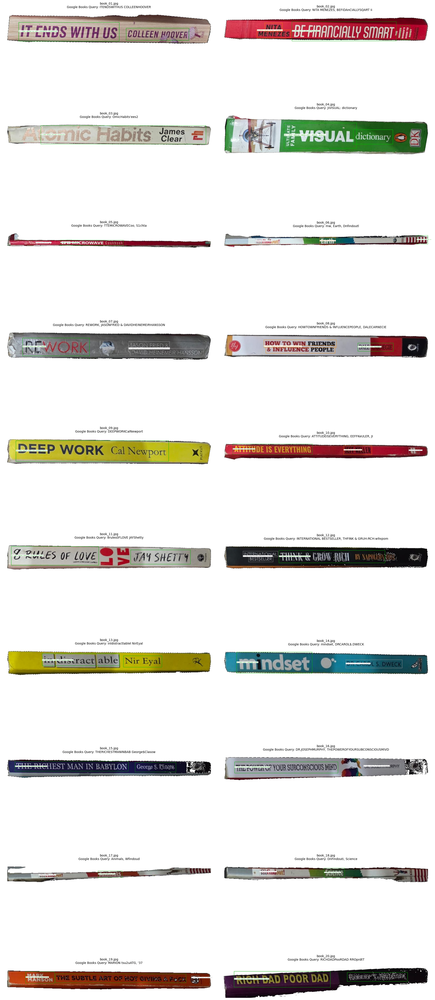

In [40]:
# ============================================================
# PHASE 15 / STEP 23
# Display all annotated spines
# ============================================================

n=len(results)

if n:
    cols=2
    row_count=math.ceil(n/cols)

    fig,axes=plt.subplots(
        row_count,
        cols,
        figsize=(20,row_count*5)
    )

    axes=np.asarray(axes).reshape(-1)

    for i,result in enumerate(results):
        ax=axes[i]

        path=(
            ANNOTATED_DIR
            / f"{Path(result['file']).stem}_typography.jpg"
        )

        image=cv2.imread(str(path))

        if image is not None:
            ax.imshow(
                cv2.cvtColor(
                    image,
                    cv2.COLOR_BGR2RGB
                )
            )

        ax.set_title(
            f"{result['file']}\n"
            f"Google Books Query: "
            f"{result['google_books_query']}",
            fontsize=10
        )
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [41]:
display(final_df)

,Book,Google Books Query,All OCR,OCR Confidence,Text Lines,Typography Groups,Detector,Deskew Angle
0,book_01.jpg,ITENDSWITHUS COLLEENHOOVER,ITENDSWITHUS COLLEENHOOVER,0.884,1,1,primary,0.00
1,book_02.jpg,"NITA MENEZES, BEFIDAnCIALLYSQART Ii",NITA | BEFIDAnCIALLYSQART Ii | MENEZES,0.849,3,2,primary,0.00
2,book_03.jpg,OmicHabits'ees2,OmicHabits'ees2,0.287,1,1,primary,0.00
3,book_04.jpg,JiVISUAL: dictionary,JiVISUAL: dictionary,0.681,1,1,primary,0.00
4,book_05.jpg,"TTEMICROWAVECoo, S1chta",TTEMICROWAVECoo | S1chta,0.461,2,2,primary,0.00
5,book_06.jpg,"mw, Earth, Dnfindoutl",mw | Earth | Dnfindoutl,0.536,3,3,primary,0.00
6,book_07.jpg,"REWORK, JASONFRIED & DAVIDHEINEMEIRHANSSON",JASONFRIED& | REWORK | DAVIDHEINEMEIRHANSSON,0.966,3,2,primary,0.00
7,book_08.jpg,"HOWTOWNFRIENDS & INFLUENCEPEOPLE, DALECARNECIE",HOWTOWNFRIENDS | DALECARNECIE | &INFLUENCEPEOPLE,0.763,3,2,primary,0.00
8,book_09.jpg,DEEPWORKCalNewport,DEEPWORKCalNewport,1.000,1,1,primary,0.00
9,book_10.jpg,"ATTITUDEISEVERYTHING, EEFFKeULER, JI",ATTITUDEISEVERYTHING | EEFFKeULER | JI,0.589,3,3,primary,0.00


# AI

## AI API Calling

In [42]:
display(final_df)

,Book,Google Books Query,All OCR,OCR Confidence,Text Lines,Typography Groups,Detector,Deskew Angle
0,book_01.jpg,ITENDSWITHUS COLLEENHOOVER,ITENDSWITHUS COLLEENHOOVER,0.884,1,1,primary,0.00
1,book_02.jpg,"NITA MENEZES, BEFIDAnCIALLYSQART Ii",NITA | BEFIDAnCIALLYSQART Ii | MENEZES,0.849,3,2,primary,0.00
2,book_03.jpg,OmicHabits'ees2,OmicHabits'ees2,0.287,1,1,primary,0.00
3,book_04.jpg,JiVISUAL: dictionary,JiVISUAL: dictionary,0.681,1,1,primary,0.00
4,book_05.jpg,"TTEMICROWAVECoo, S1chta",TTEMICROWAVECoo | S1chta,0.461,2,2,primary,0.00
5,book_06.jpg,"mw, Earth, Dnfindoutl",mw | Earth | Dnfindoutl,0.536,3,3,primary,0.00
6,book_07.jpg,"REWORK, JASONFRIED & DAVIDHEINEMEIRHANSSON",JASONFRIED& | REWORK | DAVIDHEINEMEIRHANSSON,0.966,3,2,primary,0.00
7,book_08.jpg,"HOWTOWNFRIENDS & INFLUENCEPEOPLE, DALECARNECIE",HOWTOWNFRIENDS | DALECARNECIE | &INFLUENCEPEOPLE,0.763,3,2,primary,0.00
8,book_09.jpg,DEEPWORKCalNewport,DEEPWORKCalNewport,1.000,1,1,primary,0.00
9,book_10.jpg,"ATTITUDEISEVERYTHING, EEFFKeULER, JI",ATTITUDEISEVERYTHING | EEFFKeULER | JI,0.589,3,3,primary,0.00


In [43]:
%pip install -q -U langchain-google-genai langchain-core pydantic pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.


In [44]:
# ============================================================
# BOOK SPINE OCR — GOOGLE GEMINI BATCH IDENTIFICATION
# ONE PROMPT FOR ALL GOOGLE BOOKS QUERIES
# ============================================================

import os
import json
from getpass import getpass
from pathlib import Path
from typing import Literal

import pandas as pd
from pydantic import BaseModel, Field

from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate


# ============================================================
# 1. VALIDATE EXISTING DATAFRAME
# ============================================================

if "final_df" not in globals():
    raise RuntimeError(
        "final_df not found. Run your OCR notebook first."
    )

QUERY_COLUMN = "Google Books Query"

if QUERY_COLUMN not in final_df.columns:
    raise KeyError(
        f"Missing column: {QUERY_COLUMN}"
    )

if final_df.empty:
    raise ValueError("final_df contains no book records.")

print("Total book records:", len(final_df))


# ============================================================
# 2. CONFIGURE GOOGLE GEMINI API KEY
# ============================================================

google_api_key = getpass(
    "Enter your Google Gemini API key: "
).strip()

if not google_api_key:
    raise ValueError("Google Gemini API key cannot be empty.")

os.environ["GOOGLE_API_KEY"] = google_api_key


# ============================================================
# 3. INITIALIZE GEMINI
# ============================================================

MODEL_NAME = "gemini-3.5-flash-lite"

llm = ChatGoogleGenerativeAI(
    model=MODEL_NAME,
    api_key=google_api_key,
    temperature=0,
    max_retries=2,
    timeout=180
)

print("Gemini model:", MODEL_NAME)


# ============================================================
# 4. STRUCTURED OUTPUT SCHEMAS
# ============================================================

class BookPrediction(BaseModel):
    record_id: int = Field(
        description="The original zero-based DataFrame row position."
    )

    original_query: str = Field(
        description="The exact OCR query provided in the input."
    )

    title: str = Field(
        description="The corrected, actual published book title."
    )

    author_name: str = Field(
        description="The correct published author name or names."
    )

    confidence: Literal["high", "medium", "low"] = Field(
        description="Confidence in identifying this book."
    )

    notes: str = Field(
        description="Brief explanation of the identification or ambiguity."
    )


class BatchBookPredictions(BaseModel):
    books: list[BookPrediction] = Field(
        description=(
            "Exactly one prediction for each input record, "
            "preserving every record_id."
        )
    )


# ============================================================
# 5. PROMPT — ALL BOOKS TOGETHER
# ============================================================

system_prompt = """
You are an expert bibliographic identification assistant.

You will receive a JSON list containing OCR text extracted from
multiple physical book spines.

Each record represents ONE physical book.

The field "Google Books Query" contains text that is usually
similar to the actual book title and author, but the OCR may
contain errors.

Examples of OCR errors include:
- Missing spaces between words.
- Merged title and author names.
- Incorrect capitalization.
- Incorrectly recognized letters.
- Misspelled author names.
- Incorrect punctuation.
- Subtitles mixed with author names.
- Promotional phrases mixed with title text.

YOUR OBJECTIVE:

For EVERY input record, identify the most likely actual published
book title and correct author name.

IMPORTANT RULES:

1. Analyze the entire list in one batch.
2. Use your bibliographic knowledge to identify known books.
3. Correct OCR errors instead of copying the query verbatim.
4. Separate the actual title from the author correctly.
5. Use all text available in each individual query.
6. You may use similarities between records as additional clues,
   but do not assume different records represent the same book.
7. Never merge two different records into one result.
8. Never omit a record, even if its OCR is unclear.
9. Copy each record_id exactly from the input.
10. Copy original_query exactly from the input.
11. Return one result for every input record.
12. Do not invent titles or authors when the evidence is weak.
13. If the identity is uncertain, return an empty title or author
    when necessary and use low confidence.
14. High confidence means the OCR strongly identifies a specific
    book; it is not a guarantee of correctness.
15. Return results in the same order as the input.

The query text is an OCR hypothesis, not a verified catalogue record.

Do not claim that you accessed Google Books or verified a live
bibliographic catalogue.

Return the results using the specified structured output schema.
"""


prompt = ChatPromptTemplate.from_messages([
    ("system", system_prompt),
    (
        "human",
        """
Identify the actual published title and author for every book
in the following input list.

Analyze all records together, but make an independent prediction
for each physical book.

INPUT RECORDS:
{book_records}

Return exactly one prediction for each input record.
Preserve all record_id and original_query values.
"""
    )
])


# ============================================================
# 6. CREATE STRUCTURED-OUTPUT CHAIN
# ============================================================

structured_llm = llm.with_structured_output(
    BatchBookPredictions,
    method="json_schema"
)

batch_chain = prompt | structured_llm

print("Batch identification chain ready.")


# ============================================================
# 7. PREPARE ALL QUERIES IN ONE LIST
# ============================================================

# Preserve original DataFrame positions and queries.
book_records = []

for position, query in enumerate(
    final_df[QUERY_COLUMN].tolist()
):
    if pd.isna(query):
        query = ""
    else:
        query = str(query)

    book_records.append({
        "record_id": position,
        "original_query": query
    })

# Serialize the complete list into a single prompt variable.
book_records_json = json.dumps(
    book_records,
    ensure_ascii=False,
    indent=2
)

print("Prepared records:", len(book_records))
print("All queries will be sent together.")


# ============================================================
# 8. MAKE ONE GEMINI REQUEST
# ============================================================

print("\nSending the complete book list to Gemini...")

try:
    batch_result = batch_chain.invoke({
        "book_records": book_records_json
    })

except Exception as error:
    raise RuntimeError(
        "The batch Gemini request failed. "
        "Check the API key, model availability, request size, "
        "quota, and structured-output support. "
        f"Original error: {error}"
    ) from error

print("Gemini returned a structured response.")


# ============================================================
# 9. CONVERT STRUCTURED RESPONSE TO DATAFRAME
# ============================================================

if hasattr(batch_result, "model_dump"):
    batch_data = batch_result.model_dump()
else:
    batch_data = batch_result.dict()

predictions = batch_data.get("books", [])

predictions_df = pd.DataFrame(predictions)

required_columns = [
    "record_id",
    "original_query",
    "title",
    "author_name",
    "confidence",
    "notes"
]

missing_columns = [
    column
    for column in required_columns
    if column not in predictions_df.columns
]

if missing_columns:
    raise ValueError(
        f"Gemini output is missing columns: {missing_columns}"
    )


# ============================================================
# 10. VALIDATE RESPONSE COMPLETENESS
# ============================================================

expected_ids = set(
    range(len(final_df))
)

returned_ids = predictions_df["record_id"].tolist()

if len(returned_ids) != len(set(returned_ids)):
    raise ValueError(
        "Gemini returned duplicate record_id values. "
        "Do not merge these results until the duplicates are resolved."
    )

if set(returned_ids) != expected_ids:
    missing_ids = sorted(
        expected_ids - set(returned_ids)
    )

    unexpected_ids = sorted(
        set(returned_ids) - expected_ids
    )

    raise ValueError(
        "The response does not contain exactly one result "
        "for every input record.\n"
        f"Missing IDs: {missing_ids}\n"
        f"Unexpected IDs: {unexpected_ids}\n"
        "Review the model response before proceeding."
    )

# Restore original input order.
predictions_df = (
    predictions_df
    .sort_values("record_id")
    .reset_index(drop=True)
)

# Ensure Gemini preserved each query exactly.
for position, original_query in enumerate(
    final_df[QUERY_COLUMN].tolist()
):
    if pd.isna(original_query):
        original_query = ""
    else:
        original_query = str(original_query)

    returned_query = predictions_df.loc[
        position,
        "original_query"
    ]

    if returned_query != original_query:
        raise ValueError(
            f"Query mismatch at record {position}. "
            "The output will not be merged."
        )

print(
    f"Validated {len(predictions_df)} predictions."
)


# ============================================================
# 11. BUILD PREDICTION COLUMNS
# ============================================================

def get_status(row):
    title = str(row["title"] or "").strip()
    author = str(row["author_name"] or "").strip()
    confidence = str(row["confidence"] or "low").lower()

    if not title or not author:
        return "INCOMPLETE"

    if confidence == "low":
        return "REVIEW"

    if confidence == "medium":
        return "PREDICTED"

    return "MATCHED"


predictions_df["AI Status"] = predictions_df.apply(
    get_status,
    axis=1
)

predictions_df = predictions_df.rename(
    columns={
        "title": "Predicted Title",
        "author_name": "Predicted Author",
        "confidence": "AI Confidence",
        "notes": "AI Notes"
    }
)


# ============================================================
# 12. MERGE PREDICTIONS INTO ORIGINAL final_df
# ============================================================

# Do not replace final_df with the smaller prediction DataFrame.
# Preserve all original OCR columns and row order.

new_columns = [
    "Predicted Title",
    "Predicted Author",
    "AI Confidence",
    "AI Notes",
    "AI Status"
]

final_df = final_df.drop(
    columns=[
        column
        for column in new_columns
        if column in final_df.columns
    ],
    errors="ignore"
)

predictions_for_merge = predictions_df[
    new_columns
].copy()

predictions_for_merge.index = final_df.index

final_df = pd.concat(
    [
        final_df,
        predictions_for_merge
    ],
    axis=1
)


# ============================================================
# 13. SAVE RESULTS
# ============================================================

output_dir = Path(
    globals().get(
        "OUTPUT_DIR",
        Path.cwd() / "BookSpine_OCR_Final_Output"
    )
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

output_csv = (
    output_dir / "gemini_batch_book_predictions.csv"
)

final_df.to_csv(
    output_csv,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 14. DISPLAY RESULTS
# ============================================================

display_columns = [
    column
    for column in [
        "Book",
        "Google Books Query",
        "Predicted Title",
        "Predicted Author",
        "AI Confidence",
        "AI Status"
    ]
    if column in final_df.columns
]

print("\n" + "=" * 65)
print("GEMINI BATCH IDENTIFICATION COMPLETE")
print("=" * 65)

print("Model:", MODEL_NAME)
print("Input records:", len(book_records))
print("Predictions returned:", len(predictions_df))
print("Output CSV:", output_csv)

display(
    final_df[display_columns]
)


# ============================================================
# 15. DISPLAY BOOKS REQUIRING REVIEW
# ============================================================

review_df = final_df[
    final_df["AI Status"].isin([
        "REVIEW",
        "INCOMPLETE"
    ])
].copy()

print(
    "\nBooks requiring review:",
    len(review_df)
)

if not review_df.empty:
    display(
        review_df[
            display_columns + ["AI Notes"]
        ]
    )

Total book records: 20
Enter your Google Gemini API key: ··········
Gemini model: gemini-3.5-flash-lite
Batch identification chain ready.
Prepared records: 20
All queries will be sent together.

Sending the complete book list to Gemini...
Gemini returned a structured response.
Validated 20 predictions.

GEMINI BATCH IDENTIFICATION COMPLETE
Model: gemini-3.5-flash-lite
Input records: 20
Predictions returned: 20
Output CSV: /content/BookSpine_OCR_Final_Output/gemini_batch_book_predictions.csv


,Book,Google Books Query,Predicted Title,Predicted Author,AI Confidence,AI Status
0,book_01.jpg,ITENDSWITHUS COLLEENHOOVER,It Ends with Us,Colleen Hoover,high,MATCHED
1,book_02.jpg,"NITA MENEZES, BEFIDAnCIALLYSQART Ii",Be Financially Smart,Nita Menezes,medium,PREDICTED
2,book_03.jpg,OmicHabits'ees2,Atomic Habits,James Clear,medium,PREDICTED
3,book_04.jpg,JiVISUAL: dictionary,Visual Dictionary,,medium,INCOMPLETE
4,book_05.jpg,"TTEMICROWAVECoo, S1chta",The Microwave Cookbook,,low,INCOMPLETE
5,book_06.jpg,"mw, Earth, Dnfindoutl",Earth,,low,INCOMPLETE
6,book_07.jpg,"REWORK, JASONFRIED & DAVIDHEINEMEIRHANSSON",Rework,Jason Fried and David Heinemeier Hansson,high,MATCHED
7,book_08.jpg,"HOWTOWNFRIENDS & INFLUENCEPEOPLE, DALECARNECIE",How to Win Friends and Influence People,Dale Carnegie,high,MATCHED
8,book_09.jpg,DEEPWORKCalNewport,Deep Work,Cal Newport,high,MATCHED
9,book_10.jpg,"ATTITUDEISEVERYTHING, EEFFKeULER, JI",Attitude Is Everything,Jeff Keller,high,MATCHED



Books requiring review: 6


,Book,Google Books Query,Predicted Title,Predicted Author,AI Confidence,AI Status,AI Notes
3,book_04.jpg,JiVISUAL: dictionary,Visual Dictionary,,medium,INCOMPLETE,Recognized as a visual dictionary reference book.
4,book_05.jpg,"TTEMICROWAVECoo, S1chta",The Microwave Cookbook,,low,INCOMPLETE,OCR is heavily distorted; likely a microwave c...
5,book_06.jpg,"mw, Earth, Dnfindoutl",Earth,,low,INCOMPLETE,Appears to be part of an encyclopedia or refer...
16,book_17.jpg,"Animals, Wfindoud",Animals,,low,INCOMPLETE,Likely part of a children's reference or encyc...
17,book_18.jpg,"DnFindouti, Science",Science,,low,INCOMPLETE,Likely part of a children's reference or encyc...
18,book_19.jpg,"MARION tsu2uATG, '37",,Marion,low,INCOMPLETE,Uncertain book identity from fragmented OCR.


In [45]:
'''

# ============================================================
# RETRYABLE SINGLE-BATCH GEMINI REQUEST
# ============================================================

import time
from langchain_google_genai import ChatGoogleGenerativeAI

PRIMARY_MODEL = "gemini-3.8-flash"
FALLBACK_MODEL = "gemini-3.5-flash-lite"

def create_batch_chain(model_name):
    model = ChatGoogleGenerativeAI(
        model=model_name,
        api_key=google_api_key,
        temperature=0,
        max_retries=0,
        timeout=180
    )

    structured_model = model.with_structured_output(
        BatchBookPredictions,
        method="json_schema"
    )

    return prompt | structured_model


def invoke_batch_with_fallback(book_records_json):
    models_to_try = [
        PRIMARY_MODEL,
        FALLBACK_MODEL
    ]

    last_error = None

    for model_name in models_to_try:
        chain = create_batch_chain(model_name)

        for attempt in range(3):
            try:
                print(
                    f"Trying {model_name}; "
                    f"attempt {attempt + 1}/3"
                )

                result = chain.invoke({
                    "book_records": book_records_json
                })

                print("Batch request succeeded using:", model_name)
                return result

            except Exception as error:
                last_error = error
                message = str(error).lower()

                # Don't retry authentication or permission failures.
                if any(term in message for term in [
                    "api key not valid",
                    "invalid api key",
                    "unauthenticated",
                    "permission_denied",
                    "403",
                    "401"
                ]):
                    raise

                retryable = any(term in message for term in [
                    "503",
                    "unavailable",
                    "500",
                    "502",
                    "504",
                    "429",
                    "resource_exhausted",
                    "timeout"
                ])

                if not retryable:
                    raise

                if attempt < 2:
                    wait_seconds = 2 ** (attempt + 1)

                    print(
                        f"Temporary service error. "
                        f"Waiting {wait_seconds}s..."
                    )

                    time.sleep(wait_seconds)

    raise RuntimeError(
        "Both Gemini models failed to process the batch. "
        f"Last error: {last_error}"
    )


# One successful response should contain all records.
batch_result = invoke_batch_with_fallback(
    book_records_json
)

print("Received batch response.")

'''

'\n\n# ============================================================\n# RETRYABLE SINGLE-BATCH GEMINI REQUEST\n# ============================================================\n\nimport time\nfrom langchain_google_genai import ChatGoogleGenerativeAI\n\nPRIMARY_MODEL = "gemini-3.8-flash"\nFALLBACK_MODEL = "gemini-3.5-flash-lite"\n\ndef create_batch_chain(model_name):\n    model = ChatGoogleGenerativeAI(\n        model=model_name,\n        api_key=google_api_key,\n        temperature=0,\n        max_retries=0,\n        timeout=180\n    )\n\n    structured_model = model.with_structured_output(\n        BatchBookPredictions,\n        method="json_schema"\n    )\n\n    return prompt | structured_model\n\n\ndef invoke_batch_with_fallback(book_records_json):\n    models_to_try = [\n        PRIMARY_MODEL,\n        FALLBACK_MODEL\n    ]\n\n    last_error = None\n\n    for model_name in models_to_try:\n        chain = create_batch_chain(model_name)\n\n        for attempt in range(3):\n            t

In [46]:
# ============================================================
# STEP 9 — VALIDATE, MERGE AND EXPORT BATCH PREDICTIONS
# ============================================================

import pandas as pd
import json
from pathlib import Path

# ------------------------------------------------------------
# 1. Convert Gemini's structured response to a dictionary
# ------------------------------------------------------------

if hasattr(batch_result, "model_dump"):
    batch_data = batch_result.model_dump()
elif isinstance(batch_result, dict):
    batch_data = batch_result
else:
    raise TypeError(
        f"Unexpected batch_result type: {type(batch_result)}"
    )

predictions = batch_data.get("books", [])

if not predictions:
    raise ValueError(
        "Gemini returned no book predictions. "
        "Check batch_result before continuing."
    )

predictions_df = pd.DataFrame(predictions)

print("Predictions received:", len(predictions_df))
print("Original records:", len(final_df))

# ------------------------------------------------------------
# 2. Validate required columns
# ------------------------------------------------------------

required_columns = {
    "record_id",
    "original_query",
    "title",
    "author_name",
    "confidence",
    "notes"
}

missing_columns = required_columns - set(predictions_df.columns)

if missing_columns:
    raise ValueError(
        f"Missing columns in Gemini response: {missing_columns}"
    )

# ------------------------------------------------------------
# 3. Normalize IDs and check duplicates
# ------------------------------------------------------------

predictions_df["record_id"] = pd.to_numeric(
    predictions_df["record_id"],
    errors="coerce"
)

if predictions_df["record_id"].isna().any():
    raise ValueError("Some predictions have invalid record IDs.")

predictions_df["record_id"] = (
    predictions_df["record_id"].astype(int)
)

if predictions_df["record_id"].duplicated().any():
    duplicate_ids = predictions_df.loc[
        predictions_df["record_id"].duplicated(keep=False),
        "record_id"
    ].tolist()

    raise ValueError(
        f"Duplicate record IDs returned: {duplicate_ids}"
    )

# ------------------------------------------------------------
# 4. Build the expected source records
#    Use the same record_id convention as Step 8.
# ------------------------------------------------------------

expected_df = pd.DataFrame({
    "record_id": range(len(final_df)),
    "expected_query": final_df["Google Books Query"].fillna("").astype(str).tolist()
})

# Check that every prediction refers to a real source row.
invalid_ids = set(predictions_df["record_id"]) - set(
    expected_df["record_id"]
)

if invalid_ids:
    raise ValueError(
        f"Unexpected record IDs returned by Gemini: {invalid_ids}"
    )

# ------------------------------------------------------------
# 5. Match each prediction to its original query
# ------------------------------------------------------------

validated_df = predictions_df.merge(
    expected_df,
    on="record_id",
    how="left",
    validate="one_to_one"
)

validated_df["query_matches"] = (
    validated_df["original_query"].fillna("").astype(str)
    == validated_df["expected_query"]
)

if not validated_df["query_matches"].all():
    mismatches = validated_df.loc[
        ~validated_df["query_matches"],
        ["record_id", "original_query", "expected_query"]
    ]

    raise ValueError(
        "Query mismatch detected. Do not merge these predictions.\n"
        + mismatches.to_string(index=False)
    )

# ------------------------------------------------------------
# 6. Check for missing predictions
# ------------------------------------------------------------

expected_ids = set(expected_df["record_id"])
received_ids = set(predictions_df["record_id"])

missing_ids = sorted(expected_ids - received_ids)

if missing_ids:
    print("WARNING: Missing prediction IDs:", missing_ids)
else:
    print("All source records have predictions.")

# ------------------------------------------------------------
# 7. Prepare prediction columns for merging
# ------------------------------------------------------------

prediction_columns = [
    "record_id",
    "title",
    "author_name",
    "confidence",
    "notes"
]

predictions_clean = predictions_df[prediction_columns].copy()

predictions_clean = predictions_clean.rename(columns={
    "title": "AI_Predicted_Title",
    "author_name": "AI_Predicted_Author",
    "confidence": "AI_Confidence",
    "notes": "AI_Notes"
})

# ------------------------------------------------------------
# 8. Merge predictions back into the original DataFrame
#    Positional IDs ensure predictions map to the correct rows.
# ------------------------------------------------------------

final_df = final_df.reset_index(drop=True).copy()
final_df["_record_id_step9"] = range(len(final_df))

final_df = final_df.merge(
    predictions_clean,
    left_on="_record_id_step9",
    right_on="record_id",
    how="left",
    validate="one_to_one"
)

final_df = final_df.drop(
    columns=["_record_id_step9", "record_id"]
)

# ------------------------------------------------------------
# 9. Add a simple prediction status
# ------------------------------------------------------------

final_df["AI_Prediction_Status"] = final_df[
    "AI_Predicted_Title"
].apply(
    lambda x: "Predicted" if pd.notna(x) and str(x).strip() else "Missing"
)

# ------------------------------------------------------------
# 10. Display results
# ------------------------------------------------------------

display_columns = [
    "Google Books Query",
    "AI_Predicted_Title",
    "AI_Predicted_Author",
    "AI_Confidence",
    "AI_Prediction_Status"
]

display_columns = [
    col for col in display_columns if col in final_df.columns
]

display(final_df[display_columns])

print("\nPrediction status:")
print(final_df["AI_Prediction_Status"].value_counts(dropna=False))

# ------------------------------------------------------------
# 11. Export results to CSV
# ------------------------------------------------------------

output_path = "/content/BookSpine_AI_Predictions.csv"

final_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nCSV saved successfully: {output_path}")

Predictions received: 20
Original records: 20
All source records have predictions.


,Google Books Query,AI_Predicted_Title,AI_Predicted_Author,AI_Confidence,AI_Prediction_Status
0,ITENDSWITHUS COLLEENHOOVER,It Ends with Us,Colleen Hoover,high,Predicted
1,"NITA MENEZES, BEFIDAnCIALLYSQART Ii",Be Financially Smart,Nita Menezes,medium,Predicted
2,OmicHabits'ees2,Atomic Habits,James Clear,medium,Predicted
3,JiVISUAL: dictionary,Visual Dictionary,,medium,Predicted
4,"TTEMICROWAVECoo, S1chta",The Microwave Cookbook,,low,Predicted
5,"mw, Earth, Dnfindoutl",Earth,,low,Predicted
6,"REWORK, JASONFRIED & DAVIDHEINEMEIRHANSSON",Rework,Jason Fried and David Heinemeier Hansson,high,Predicted
7,"HOWTOWNFRIENDS & INFLUENCEPEOPLE, DALECARNECIE",How to Win Friends and Influence People,Dale Carnegie,high,Predicted
8,DEEPWORKCalNewport,Deep Work,Cal Newport,high,Predicted
9,"ATTITUDEISEVERYTHING, EEFFKeULER, JI",Attitude Is Everything,Jeff Keller,high,Predicted



Prediction status:
AI_Prediction_Status
Predicted    19
Missing       1
Name: count, dtype: int64

CSV saved successfully: /content/BookSpine_AI_Predictions.csv


In [47]:
# ============================================================
# CELL 1: PREPARE BOOK CATALOGUE FOR RECOMMENDATIONS
# Run after Cell 68 of the original notebook
# ============================================================

import pandas as pd
import json
import os
import html
import requests
import ipywidgets as widgets

from IPython.display import display, HTML
from getpass import getpass

if "final_df" not in globals():
    raise RuntimeError("Run the original book identification pipeline first.")

# Use the corrected title and author produced by Gemini.
title_column = next(
    (c for c in ["AI_Predicted_Title", "title", "Book Title", "book_title"]
     if c in final_df.columns),
    None
)

author_column = next(
    (c for c in ["AI_Predicted_Author", "author_name", "Author Name", "author"]
     if c in final_df.columns),
    None
)

if title_column is None or author_column is None:
    raise KeyError(
        "Could not find corrected title and author columns. "
        f"Available columns: {list(final_df.columns)}"
    )

# Create clean candidate catalogue.
catalog_df = pd.DataFrame({
    "title": final_df[title_column],
    "author": final_df[author_column]
}).fillna("")

catalog_df["title"] = catalog_df["title"].astype(str).str.strip()
catalog_df["author"] = catalog_df["author"].astype(str).str.strip()

invalid_values = {"", "nan", "none", "unknown", "null", "n/a"}

catalog_df = catalog_df[
    ~catalog_df["title"].str.lower().isin(invalid_values)
    & ~catalog_df["author"].str.lower().isin(invalid_values)
].copy()

catalog_df = catalog_df.drop_duplicates(
    subset=["title", "author"]
).reset_index(drop=True)

catalog_df["book_id"] = [
    f"BOOK_{i:03d}" for i in range(1, len(catalog_df) + 1)
]

# Put the ID first for easy inspection.
catalog_df = catalog_df[["book_id", "title", "author"]]

if len(catalog_df) < 3:
    raise ValueError(
        f"Only {len(catalog_df)} complete books found. "
        "At least 3 books with both title and author are required."
    )

# Send only valid books to Gemini.
candidate_books = catalog_df.to_dict(orient="records")

print("Total valid candidate books:", len(candidate_books))
display(catalog_df)

Total valid candidate books: 14


,book_id,title,author
0,BOOK_001,It Ends with Us,Colleen Hoover
1,BOOK_002,Be Financially Smart,Nita Menezes
2,BOOK_003,Atomic Habits,James Clear
3,BOOK_004,Rework,Jason Fried and David Heinemeier Hansson
4,BOOK_005,How to Win Friends and Influence People,Dale Carnegie
5,BOOK_006,Deep Work,Cal Newport
6,BOOK_007,Attitude Is Everything,Jeff Keller
7,BOOK_008,8 Rules of Love,Jay Shetty
8,BOOK_009,Think and Grow Rich,Napoleon Hill
9,BOOK_010,Indistractable,Nir Eyal


In [48]:
# ============================================================
# CELL 2: USER QUESTIONNAIRE
# Q1: Select up to 3
# Q2: Select up to 5
# Q3 and Q4: Single choice
# Q5: Optional text
# ============================================================

q1_options = [
    "Learn something useful",
    "Improve my career or business",
    "Understand myself better",
    "Build better habits or discipline",
    "Explore new ideas and perspectives",
    "Be entertained and escape reality",
    "Experience a powerful emotional story",
    "Improve my relationships",
    "Understand society, history, or human behavior",
    "Get inspired or motivated"
]

q2_options = [
    "Psychology and human behavior",
    "Philosophy and meaning of life",
    "Technology and AI",
    "Business and entrepreneurship",
    "Personal finance and investing",
    "Science and nature",
    "History and civilizations",
    "Politics and society",
    "Productivity and habits",
    "Relationships and communication",
    "Fantasy and world-building",
    "Mystery, crime, and thrillers",
    "Literary fiction and human experiences",
    "Biographies and real-life stories",
    "Spirituality and mindfulness",
    "Health and fitness",
    "Art and creativity",
    "Travel and culture"
]

q3_options = [
    "Practical and actionable — I want to use what I learn.",
    "Deep and thought-provoking — I like challenging ideas.",
    "Emotional and immersive — I want to feel something.",
    "Fast-paced and entertaining — keep me hooked.",
    "Informative and fact-rich — I enjoy understanding how things work.",
    "Reflective and philosophical — I like questioning life and assumptions.",
    "It depends on my mood."
]

q4_options = [
    "Develop new skills or knowledge.",
    "Make better decisions and think clearly.",
    "Grow professionally or build a business.",
    "Understand myself and my motivations.",
    "Build confidence and resilience.",
    "Improve my relationships and communication.",
    "Explore meaning, purpose, or values.",
    "Relax, have fun, or escape into a story.",
    "Something else."
]

q1 = widgets.SelectMultiple(
    options=q1_options,
    description="Q1",
    rows=7,
    layout=widgets.Layout(width="100%"),
    style={"description_width": "45px"}
)

q2 = widgets.SelectMultiple(
    options=q2_options,
    description="Q2",
    rows=9,
    layout=widgets.Layout(width="100%"),
    style={"description_width": "45px"}
)

q3 = widgets.Dropdown(
    options=[("Choose one...", "")] + [(x, x) for x in q3_options],
    description="Q3",
    layout=widgets.Layout(width="100%"),
    style={"description_width": "45px"}
)

q4 = widgets.Dropdown(
    options=[("Choose one...", "")] + [(x, x) for x in q4_options],
    description="Q4",
    layout=widgets.Layout(width="100%"),
    style={"description_width": "45px"}
)

q5 = widgets.Textarea(
    placeholder=(
        "Describe a book that changed your perspective, a topic you "
        "want to explore, or the kind of book you wish you could find."
    ),
    description="Q5",
    rows=4,
    layout=widgets.Layout(width="100%"),
    style={"description_width": "45px"}
)

submit_button = widgets.Button(
    description="Save Answers",
    button_style="primary",
    icon="check"
)

form_output = widgets.Output()

user_answers = None


def save_questionnaire(_):
    global user_answers

    with form_output:
        form_output.clear_output()

        if not 1 <= len(q1.value) <= 3:
            print("Q1: Select between 1 and 3 options.")
            return

        if not 1 <= len(q2.value) <= 5:
            print("Q2: Select between 1 and 5 options.")
            return

        if not q3.value:
            print("Please answer Q3.")
            return

        if not q4.value:
            print("Please answer Q4.")
            return

        user_answers = {
            "Q1_goals": list(q1.value),
            "Q2_topics": list(q2.value),
            "Q3_reading_experience": q3.value,
            "Q4_current_need": q4.value,
            "Q5_additional_preferences": q5.value.strip() or None
        }

        print("Answers saved successfully.")
        print(json.dumps(user_answers, indent=2, ensure_ascii=False))


submit_button.on_click(save_questionnaire)

questionnaire = widgets.VBox([
    widgets.HTML("<h3>Q1. What are you looking for in your next book?</h3>"),
    widgets.HTML("<i>Select up to 3 options. Use Ctrl+click to select multiple.</i>"),
    q1,

    widgets.HTML("<h3>Q2. Which topics genuinely excite you?</h3>"),
    widgets.HTML("<i>Select up to 5 options.</i>"),
    q2,

    widgets.HTML("<h3>Q3. What kind of reading experience do you enjoy most?</h3>"),
    q3,

    widgets.HTML(
        "<h3>Q4. If one book could help you with one thing in your life right now, "
        "what would it be?</h3>"
    ),
    q4,

    widgets.HTML("<h3>Q5. Is there anything else we should know?</h3>"),
    q5,

    submit_button,
    form_output
])

display(questionnaire)

In [50]:
# ============================================================
# CELL 3: GEMINI BOOK RECOMMENDATION + GOOGLE BOOKS METADATA
#
# Gemini model: gemini-3.5-flash-lite
#
# Features:
# 1. Collect user answers and candidate books
# 2. Recommend exactly 3 distinct books
# 3. Fetch ISBN-13 and ISBN-10
# 4. Convert valid ISBN-10 to equivalent ISBN-13 if needed
# 5. Search multiple Google Books queries
# 6. Deduplicate results and rank editions by publication date
# 7. Retrieve publisher, date, Google Books URL and cover URL
# 8. Save the final results as JSON
# ============================================================

%pip install -q google-genai pydantic requests

import os
import re
import json
import time
import requests

from getpass import getpass
from difflib import SequenceMatcher
from pydantic import BaseModel, Field
from google import genai
from google.genai import types


# ============================================================
# PART 1: VALIDATE INPUTS
# ============================================================

if "user_answers" not in globals() or user_answers is None:
    raise RuntimeError(
        "Run Cell 2 and complete the questionnaire first."
    )

if "candidate_books" not in globals() or not candidate_books:
    raise RuntimeError(
        "Run Cell 1 to prepare the candidate book catalogue first."
    )

if len(candidate_books) < 3:
    raise ValueError(
        "At least 3 candidate books are required."
    )


# ============================================================
# PART 2: GEMINI API CONFIGURATION
# ============================================================

MODEL_NAME = "gemini-3.5-flash-lite"

gemini_api_key = (
    os.environ.get("GOOGLE_API_KEY")
    or globals().get("google_api_key")
    or ""
)

if not gemini_api_key:
    gemini_api_key = getpass(
        "Enter your Gemini API key: "
    ).strip()

if not gemini_api_key:
    raise ValueError("Gemini API key is required.")

gemini_client = genai.Client(
    api_key=gemini_api_key
)


# ============================================================
# PART 3: STRUCTURED GEMINI RESPONSE SCHEMA
# ============================================================

class BookRecommendation(BaseModel):
    book_id: str = Field(
        description="Exact book_id from the candidate catalogue."
    )

    reasons: list[str] = Field(
        description=(
            "Exactly 3 concise reasons explaining personal relevance, "
            "practical or emotional benefits, and established reader appeal."
        )
    )


class BookRecommendationResponse(BaseModel):
    recommendations: list[BookRecommendation] = Field(
        description="Exactly 3 distinct book recommendations."
    )


# ============================================================
# PART 4: GENERATE PERSONALIZED RECOMMENDATIONS
# ============================================================

recommendation_prompt = f"""
You are an intelligent, personalized book recommendation assistant.

Analyze the user's answers and recommend the BEST 3 books from
the supplied candidate catalogue.

USER QUESTIONNAIRE ANSWERS:
{json.dumps(user_answers, ensure_ascii=False, indent=2)}

AVAILABLE BOOKS:
{json.dumps(candidate_books, ensure_ascii=False, indent=2)}

STRICT RULES:

1. Recommend exactly 3 different books.
2. Select ONLY books from the supplied candidate catalogue.
3. Copy each book_id exactly.
4. Consider the user's goals, interests, reading preferences,
   current needs, and additional comments.
5. Prioritize relevance over popularity alone.
6. Provide exactly 3 reasons for every recommendation.
7. Explain:
   - Why the book matches the user's preferences.
   - How the book may help or benefit the reader.
   - Why the book has established reader appeal.
8. Do not invent sales figures, awards, rankings, or personal details.
9. Avoid repetitive reasons across recommendations.
10. Return data matching the requested structured schema.
"""

gemini_response = gemini_client.models.generate_content(
    model=MODEL_NAME,
    contents=recommendation_prompt,
    config=types.GenerateContentConfig(
        temperature=0.2,
        response_mime_type="application/json",
        response_schema=BookRecommendationResponse
    )
)


# ============================================================
# PART 5: PARSE AND VALIDATE GEMINI RESPONSE
# ============================================================

parsed_response = gemini_response.parsed

if parsed_response is not None:

    if hasattr(parsed_response, "model_dump"):
        response_data = parsed_response.model_dump()

    elif isinstance(parsed_response, dict):
        response_data = parsed_response

    else:
        response_data = json.loads(gemini_response.text)

else:

    if not gemini_response.text:
        raise RuntimeError(
            "Gemini returned no parseable response. "
            "Check API availability and model configuration."
        )

    response_data = json.loads(gemini_response.text)


raw_recommendations = response_data.get(
    "recommendations", []
)

if len(raw_recommendations) != 3:
    raise ValueError(
        f"Expected 3 recommendations; received "
        f"{len(raw_recommendations)}."
    )


# Catalogue validation.
catalog_lookup = {
    book["book_id"]: book
    for book in candidate_books
}

recommendations = []
selected_book_ids = set()

for item in raw_recommendations:

    book_id = item["book_id"]

    if book_id not in catalog_lookup:
        raise ValueError(
            f"Gemini returned an unknown book ID: {book_id}"
        )

    if book_id in selected_book_ids:
        raise ValueError(
            f"Gemini returned duplicate book ID: {book_id}"
        )

    selected_book_ids.add(book_id)

    reasons = [
        str(reason).strip()
        for reason in item.get("reasons", [])
        if str(reason).strip()
    ]

    if len(reasons) != 3:
        raise ValueError(
            f"{book_id} must contain exactly 3 reasons; "
            f"received {len(reasons)}."
        )

    candidate = catalog_lookup[book_id]

    recommendations.append({
        "book_id": book_id,
        "title": candidate["title"],
        "author_name": candidate["author"],
        "book_image_url": None,
        "isbn_13": None,
        "isbn_10": None,
        "isbn_13_source": None,
        "publisher": None,
        "published_date": None,
        "google_books_volume_id": None,
        "google_books_url": None,
        "edition_title": None,
        "edition_author_name": None,
        "reasons": reasons
    })

print("Gemini recommendation generation completed.")
print("Model:", MODEL_NAME)
print("Recommendations:", len(recommendations))


# ============================================================
# PART 6: GOOGLE BOOKS API CONFIGURATION
# ============================================================

GOOGLE_BOOKS_API_URL = (
    "https://www.googleapis.com/books/v1/volumes"
)

google_books_api_key = (
    os.environ.get("GOOGLE_BOOKS_API_KEY")
    or globals().get("GOOGLE_BOOKS_API_KEY")
    or globals().get("google_books_api_key")
    or ""
)

if not google_books_api_key:
    google_books_api_key = getpass(
        "Enter your Google Books API key: "
    ).strip()

if not google_books_api_key:
    raise ValueError("Google Books API key is required.")

google_books_session = requests.Session()

# Limit queries to control API consumption.
MAX_RESULTS_PER_PAGE = 40
MAX_PAGES_PER_QUERY = 2

# Do not continue making requests after a persistent 429.
GOOGLE_BOOKS_RATE_LIMITED = False

COVER_PRIORITY = [
    "extraLarge",
    "large",
    "medium",
    "small",
    "thumbnail",
    "smallThumbnail"
]


# ============================================================
# PART 7: TEXT MATCHING FUNCTIONS
# ============================================================

def normalize_book_text(value):
    """
    Normalize punctuation, capitalization and ampersands.
    This helps match variants such as:
    'How to Win Friends and Influence People'
    'How to Win Friends & Influence People'
    """

    value = str(value or "").lower()
    value = value.replace("&", " and ")

    return re.sub(r"[^a-z0-9]", "", value)


def book_title_similarity(requested_title, returned_title):

    requested = normalize_book_text(requested_title)
    returned = normalize_book_text(returned_title)

    if not requested or not returned:
        return 0.0

    if requested == returned:
        return 1.0

    if requested in returned:
        return 0.98

    return SequenceMatcher(
        None, requested, returned
    ).ratio()


def book_author_similarity(requested_author, returned_authors):
    """
    Compare names using both character similarity and word overlap.
    Also handles names whose components appear in different orders.
    """

    requested_author = str(requested_author or "")

    requested_words = set(
        re.findall(r"[a-z0-9]+", requested_author.lower())
    )

    if not requested_words:
        return 0.0

    best_score = 0.0

    for returned_author in (returned_authors or []):

        returned_author = str(returned_author)

        returned_words = set(
            re.findall(r"[a-z0-9]+", returned_author.lower())
        )

        if not returned_words:
            continue

        if (
            normalize_book_text(requested_author)
            == normalize_book_text(returned_author)
        ):
            return 1.0

        character_score = SequenceMatcher(
            None,
            normalize_book_text(requested_author),
            normalize_book_text(returned_author)
        ).ratio()

        # Word overlap handles names such as "Carnegie, Dale".
        overlap_score = (
            len(requested_words & returned_words)
            / len(requested_words)
        )

        best_score = max(
            best_score,
            character_score,
            overlap_score
        )

    return best_score


def publication_date_key(date_string):
    """
    Convert YYYY, YYYY-MM or YYYY-MM-DD to a sortable tuple.
    Unknown dates sort below known dates.
    """

    match = re.match(
        r"^(\d{4})(?:-(\d{1,2}))?(?:-(\d{1,2}))?",
        str(date_string or "").strip()
    )

    if not match:
        return (0, 0, 0)

    return (
        int(match.group(1)),
        int(match.group(2) or 0),
        int(match.group(3) or 0)
    )


# ============================================================
# PART 8: ISBN VALIDATION AND ISBN-10 CONVERSION
# ============================================================

def is_valid_isbn13(isbn):
    """Validate the ISBN-13 checksum."""

    isbn = re.sub(r"[-\s]", "", str(isbn or ""))

    if not re.fullmatch(r"\d{13}", isbn):
        return False

    weighted_sum = sum(
        int(digit) * (1 if index % 2 == 0 else 3)
        for index, digit in enumerate(isbn[:12])
    )

    expected_check_digit = (10 - weighted_sum % 10) % 10

    return expected_check_digit == int(isbn[-1])


def is_valid_isbn10(isbn):
    """Validate the ISBN-10 checksum, including X as the check digit."""

    isbn = re.sub(r"[-\s]", "", str(isbn or "")).upper()

    if not re.fullmatch(r"\d{9}[\dX]", isbn):
        return False

    total = 0

    for index, character in enumerate(isbn):
        digit = 10 if character == "X" else int(character)
        total += digit * (10 - index)

    return total % 11 == 0


def isbn10_to_isbn13(isbn10):
    """
    Convert a valid ISBN-10 to its equivalent 978-prefixed ISBN-13.
    Returns None for invalid input.
    """

    isbn10 = re.sub(
        r"[-\s]", "", str(isbn10 or "")
    ).upper()

    if not is_valid_isbn10(isbn10):
        return None

    # ISBN-10 conversion applies to the 978 prefix.
    base = "978" + isbn10[:9]

    weighted_sum = sum(
        int(digit) * (1 if index % 2 == 0 else 3)
        for index, digit in enumerate(base)
    )

    check_digit = (10 - weighted_sum % 10) % 10

    converted = base + str(check_digit)

    return converted if is_valid_isbn13(converted) else None


def extract_isbn_metadata(volume_info):
    """
    Return ISBN-13 directly from Google Books when present.
    Otherwise derive the equivalent ISBN-13 from a valid ISBN-10.
    """

    identifiers = volume_info.get(
        "industryIdentifiers", []
    ) or []

    isbn13_candidates = [
        item.get("identifier")
        for item in identifiers
        if item.get("type") == "ISBN_13"
    ]

    isbn10_candidates = [
        item.get("identifier")
        for item in identifiers
        if item.get("type") == "ISBN_10"
    ]

    isbn13 = next(
        (
            re.sub(r"[-\s]", "", value)
            for value in isbn13_candidates
            if is_valid_isbn13(value)
        ),
        None
    )

    isbn10 = next(
        (
            re.sub(r"[-\s]", "", value).upper()
            for value in isbn10_candidates
            if is_valid_isbn10(value)
        ),
        None
    )

    if isbn13:
        source = "Google Books ISBN_13"

    elif isbn10:
        isbn13 = isbn10_to_isbn13(isbn10)
        source = (
            "Converted from Google Books ISBN_10"
            if isbn13 else None
        )

    else:
        source = None

    return {
        "isbn_13": isbn13,
        "isbn_10": isbn10,
        "isbn_13_source": source
    }


# ============================================================
# PART 9: GOOGLE BOOKS API SEARCH WITH PAGINATION
# ============================================================

def search_google_books(query):
    """
    Search Google Books with pagination.
    MaxResults is capped at 40 by the API.
    """

    global GOOGLE_BOOKS_RATE_LIMITED

    if GOOGLE_BOOKS_RATE_LIMITED:
        return []

    all_volumes = {}
    start_index = 0

    for page_number in range(MAX_PAGES_PER_QUERY):

        params = {
            "q": query,
            "key": google_books_api_key,
            "maxResults": MAX_RESULTS_PER_PAGE,
            "startIndex": start_index,
            "orderBy": "newest",
            "printType": "books"
        }

        try:
            response = google_books_session.get(
                GOOGLE_BOOKS_API_URL,
                params=params,
                timeout=25
            )

        except requests.RequestException as error:
            print(
                f"Request failed for query {query!r}: {error}"
            )
            return list(all_volumes.values())

        if response.status_code == 429:
            GOOGLE_BOOKS_RATE_LIMITED = True

            print(
                "\nGoogle Books returned HTTP 429. "
                "Additional API requests have been stopped. "
                "Check your Google Cloud API quota."
            )

            return list(all_volumes.values())

        if response.status_code != 200:
            print(
                f"Google Books HTTP {response.status_code}: "
                f"{response.text[:400]}"
            )
            return list(all_volumes.values())

        try:
            data = response.json()
        except ValueError:
            print("Google Books returned invalid JSON.")
            return list(all_volumes.values())

        if data.get("error"):
            print("Google Books API error:", data["error"])
            return list(all_volumes.values())

        items = data.get("items", [])
        total_items = data.get("totalItems", 0)

        print(
            f"Query: {query!r} | Page: {page_number + 1} | "
            f"Total: {total_items} | Returned: {len(items)}"
        )

        for volume in items:
            volume_id = volume.get("id")

            if volume_id:
                all_volumes[volume_id] = volume

        if not items:
            break

        start_index += len(items)

        if start_index >= total_items:
            break

        # If fewer records than requested are returned, there is
        # no reason to continue paging this query.
        if len(items) < MAX_RESULTS_PER_PAGE:
            break

        time.sleep(0.25)

    return list(all_volumes.values())


# ============================================================
# PART 10: RETRIEVE THE HIGHEST-RESOLUTION COVER
# ============================================================

def get_google_books_cover(image_links):
    for size in COVER_PRIORITY:

        image_url = (image_links or {}).get(size)

        if image_url:
            return {
                "url": image_url.replace(
                    "http://", "https://", 1
                ),
                "size": size
            }

    return {
        "url": None,
        "size": None
    }


# ============================================================
# PART 11: GET ALL MATCHING ISBN EDITIONS
# ============================================================

def get_book_isbn_metadata(book_title, author_name):
    """
    Search all query variants, combine and deduplicate the complete
    result sets, and rank matching editions after searching.

    Query variants:
      1. Exact title phrase + author phrase
      2. Exact title phrase
      3. Unquoted title + author

    Up to MAX_PAGES_PER_QUERY pages are requested for each query.
    """

    query_options = [
        f'"{book_title}" "{author_name}"',
        f'"{book_title}"',
        f"{book_title} {author_name}"
    ]

    # Remove duplicate query strings without changing their order.
    query_options = list(dict.fromkeys(query_options))

    all_volumes = {}

    print("\n" + "-" * 65)
    print(f"ISBN/edition lookup: {book_title} — {author_name}")

    # IMPORTANT: Do NOT stop when the first query finds a match.
    # Collect results from every query before ranking editions.
    for query in query_options:

        if GOOGLE_BOOKS_RATE_LIMITED:
            break

        query_volumes = search_google_books(query)

        for volume in query_volumes:
            volume_id = volume.get("id")

            if volume_id:
                all_volumes[volume_id] = volume

        time.sleep(0.25)

    if not all_volumes:
        print("No Google Books records were retrieved.")
        return None

    candidates = []

    # Rank only after all query results have been combined.
    for volume in all_volumes.values():

        info = volume.get("volumeInfo", {})

        result_title = info.get("title", "")
        subtitle = info.get("subtitle", "")
        full_title = f"{result_title} {subtitle}".strip()

        authors = info.get("authors", []) or []

        title_score = book_title_similarity(
            book_title,
            full_title
        )

        author_score = book_author_similarity(
            author_name,
            authors
        )

        # Match thresholds prevent unrelated books from being chosen.
        if title_score < 0.75:
            continue

        if author_score < 0.40:
            continue

        isbn_data = extract_isbn_metadata(info)

        # Only select editions for which ISBN-13 is available
        # directly or can be derived from a valid ISBN-10.
        if not isbn_data["isbn_13"]:
            continue

        cover = get_google_books_cover(
            info.get("imageLinks", {})
        )

        published_date = info.get("publishedDate", "")

        candidates.append({
            "isbn_13": isbn_data["isbn_13"],
            "isbn_10": isbn_data["isbn_10"],
            "isbn_13_source": isbn_data["isbn_13_source"],
            "edition_title": result_title,
            "author_name": ", ".join(authors),
            "publisher": info.get("publisher"),
            "published_date": published_date,
            "date_key": publication_date_key(published_date),
            "google_books_volume_id": volume.get("id"),
            "google_books_url": info.get(
                "infoLink",
                f"https://books.google.com/books?id={volume.get('id')}"
            ),
            "book_image_url": cover["url"],
            "cover_size": cover["size"],
            "title_score": title_score,
            "author_score": author_score
        })

    if not candidates:

        print(
            "\nNo qualifying edition with ISBN-13 was found.\n"
            "Sample Google Books records for diagnosis:"
        )

        for volume in list(all_volumes.values())[:12]:

            info = volume.get("volumeInfo", {})

            print({
                "title": info.get("title"),
                "authors": info.get("authors"),
                "publishedDate": info.get("publishedDate"),
                "industryIdentifiers": info.get(
                    "industryIdentifiers"
                ),
                "imageLinks": list(
                    (info.get("imageLinks") or {}).keys()
                )
            })

        return None

    # Sort all query variants together:
    # 1. Latest known publication date
    # 2. Best title match
    # 3. Best author match
    # 4. Prefer a record with a cover when scores are tied
    candidates.sort(
        key=lambda item: (
            item["date_key"],
            item["title_score"],
            item["author_score"],
            int(bool(item["book_image_url"]))
        ),
        reverse=True
    )

    best = candidates[0]

    print("\nSELECTED GOOGLE BOOKS EDITION")
    print("Title:", best["edition_title"])
    print("Author:", best["author_name"])
    print("ISBN-13:", best["isbn_13"])
    print("ISBN-10:", best["isbn_10"] or "Unavailable")
    print("ISBN-13 source:", best["isbn_13_source"])
    print("Publisher:", best["publisher"] or "Unknown")
    print("Publication date:", best["published_date"] or "Unknown")
    print("Matching editions:", len(candidates))
    print("Cover size:", best["cover_size"] or "Unavailable")
    print("Google Books volume ID:", best["google_books_volume_id"])

    print("\nOther matching editions:")
    for alternative in candidates[1:4]:
        print(
            f"- {alternative['edition_title']} | "
            f"{alternative['published_date'] or 'Unknown date'} | "
            f"ISBN-13: {alternative['isbn_13']}"
        )

    # Remove internal ranking key from public metadata.
    best.pop("date_key", None)

    return best


# ============================================================
# PART 12: ENRICH THE THREE RECOMMENDED BOOKS
# ============================================================

for book in recommendations:

    metadata = get_book_isbn_metadata(
        book["title"],
        book["author_name"]
    )

    if metadata:

        book["edition_title"] = metadata["edition_title"]
        book["edition_author_name"] = metadata["author_name"]

        book["isbn_13"] = metadata["isbn_13"]
        book["isbn_10"] = metadata["isbn_10"]
        book["isbn_13_source"] = metadata["isbn_13_source"]

        book["publisher"] = metadata["publisher"]
        book["published_date"] = metadata["published_date"]

        book["google_books_volume_id"] = (
            metadata["google_books_volume_id"]
        )

        book["google_books_url"] = (
            metadata["google_books_url"]
        )

        book["book_image_url"] = (
            metadata["book_image_url"]
        )

        book["cover_size"] = metadata["cover_size"]

    else:

        book["edition_title"] = None
        book["edition_author_name"] = None

        book["isbn_13"] = None
        book["isbn_10"] = None
        book["isbn_13_source"] = None

        book["publisher"] = None
        book["published_date"] = None

        book["google_books_volume_id"] = None
        book["google_books_url"] = None

        book["book_image_url"] = None
        book["cover_size"] = None

    if GOOGLE_BOOKS_RATE_LIMITED:
        print(
            "\nGoogle Books rate limit reached. "
            "Stopping remaining ISBN lookups."
        )
        break


# ============================================================
# PART 13: DISPLAY RECOMMENDATIONS AND COVER IMAGES
# ============================================================

from IPython.display import display, HTML
import html as html_module

for index, book in enumerate(recommendations, start=1):

    print("\n" + "=" * 70)

    print(f"Book {index}")
    print("Book ID:", book["book_id"])
    print("Recommended title:", book["title"])
    print("Recommended author:", book["author_name"])

    print("Selected edition:", book["edition_title"] or "Unavailable")
    print(
        "Edition author:",
        book["edition_author_name"] or "Unavailable"
    )

    print("ISBN-13:", book["isbn_13"] or "Not available")
    print("ISBN-10:", book["isbn_10"] or "Not available")

    print("ISBN-13 source:", book["isbn_13_source"] or "Unavailable")

    print("Publisher:", book["publisher"] or "Unavailable")
    print("Publication date:", book["published_date"] or "Unknown")

    print(
        "Google Books volume ID:",
        book["google_books_volume_id"] or "Unavailable"
    )

    print("Google Books URL:", book["google_books_url"])
    print("Book image URL:", book["book_image_url"] or "Unavailable")
    print("Cover size:", book["cover_size"] or "Unavailable")

    print("\nReasons:")
    for reason in book["reasons"]:
        print("-", reason)

    if book.get("book_image_url"):

        safe_url = html_module.escape(
            book["book_image_url"],
            quote=True
        )

        safe_title = html_module.escape(
            book.get("edition_title") or book["title"]
        )

        display(HTML(f"""
            <div style="margin: 12px 0 24px 0;">
                <img
                    src="{safe_url}"
                    alt="{safe_title}"
                    style="
                        max-width: 240px;
                        max-height: 340px;
                        object-fit: contain;
                    "
                />
            </div>
        """))


# ============================================================
# PART 14: SAVE COMPLETE RESULTS AS JSON
# ============================================================

output_path = "/content/book_recommendations.json"

with open(output_path, "w", encoding="utf-8") as file:

    json.dump(
        recommendations,
        file,
        ensure_ascii=False,
        indent=2
    )

print("\n" + "=" * 70)
print("Gemini recommendation generation completed.")
print("Model:", MODEL_NAME)
print("Total recommendations:", len(recommendations))
print("Saved to:", output_path)
print("Cover source: Google Books API.")

Gemini recommendation generation completed.
Model: gemini-3.5-flash-lite
Recommendations: 3

-----------------------------------------------------------------
ISBN/edition lookup: Mindset: The New Psychology of Success — Carol S. Dweck
Query: '"Mindset: The New Psychology of Success" "Carol S. Dweck"' | Page: 1 | Total: 49 | Returned: 20
Google Books HTTP 503: {
  "error": {
    "code": 503,
    "message": "Service temporarily unavailable.",
    "errors": [
      {
        "message": "Service temporarily unavailable.",
        "domain": "global",
        "reason": "backendFailed"
      }
    ]
  }
}

Query: 'Mindset: The New Psychology of Success Carol S. Dweck' | Page: 1 | Total: 44 | Returned: 20

SELECTED GOOGLE BOOKS EDITION
Title: Mindset: The New Psychology of Success (Edisi Bahasa Melayu)
Author: CAROL S. DWECK
ISBN-13: 9786294930858
ISBN-10: 6294930855
ISBN-13 source: Google Books ISBN_13
Publisher: PTS Publishing House Sdn. Bhd.
Publication date: 2024-11-26
Matching editions: 


Book 2
Book ID: BOOK_003
Recommended title: Atomic Habits
Recommended author: James Clear
Selected edition: The Atomic Habits Workbook
Edition author: James Clear
ISBN-13: 9798217180509
ISBN-10: Not available
ISBN-13 source: Google Books ISBN_13
Publisher: Penguin Group
Publication date: 2025-12-09
Google Books volume ID: 5GSBEQAAQBAJ
Google Books URL: http://books.google.com.sg/books?id=5GSBEQAAQBAJ&dq=%22Atomic+Habits%22&hl=&as_pt=BOOKS&source=gbs_api
Book image URL: https://books.google.com/books/content?id=5GSBEQAAQBAJ&printsec=frontcover&img=1&zoom=1&edge=curl&source=gbs_api
Cover size: thumbnail

Reasons:
- It directly addresses your desire to understand human behavior through the science of habit formation and neurological cues.
- It offers practical, step-by-step systems to optimize your daily routines and improve your decision-making clarity.
- It has achieved massive global popularity and critical acclaim for translating complex behavioral science into easy-to-apply strategi


Book 3
Book ID: BOOK_010
Recommended title: Indistractable
Recommended author: Nir Eyal
Selected edition: Indistractable, Updated Edition
Edition author: Nir Eyal
ISBN-13: 9781637747827
ISBN-10: 1637747829
ISBN-13 source: Google Books ISBN_13
Publisher: Simon and Schuster
Publication date: 2025-11-04
Google Books volume ID: fySNEQAAQBAJ
Google Books URL: http://books.google.com.sg/books?id=fySNEQAAQBAJ&dq=%22Indistractable%22&hl=&as_pt=BOOKS&source=gbs_api
Book image URL: https://books.google.com/books/content?id=fySNEQAAQBAJ&printsec=frontcover&img=1&zoom=1&edge=curl&source=gbs_api
Cover size: thumbnail

Reasons:
- It explores the deep psychological triggers behind distraction, satisfying your quest to comprehend human behavior.
- It equips you with powerful internal and external tactics to eliminate distractions and make intentional, clear-headed choices.
- It is highly regarded by modern professionals and psychologists as a crucial guide for navigating our hyper-connected world.



Gemini recommendation generation completed.
Model: gemini-3.5-flash-lite
Total recommendations: 3
Saved to: /content/book_recommendations.json
Cover source: Google Books API.


In [51]:
# ============================================================
# CELL 3: GEMINI RECOMMENDATIONS + POPULAR EDITION LOOKUP
#
# Gemini:
#   Recommends 3 books based on the questionnaire.
#
# Google Books:
#   Searches multiple editions of each recommended book.
#   Selects the most popular eligible edition using ratingsCount.
#   Returns that edition's ISBN-13 and cover image.
#
# Popularity ranking:
#   1. Number of Google Books ratings (descending)
#   2. Average rating (descending)
#   3. Title and author match quality
#   4. Cover resolution
#   5. Publication date (tie-breaker only)
# ============================================================

%pip install -q google-genai pydantic requests

import os
import re
import json
import time
import html
import requests

from getpass import getpass
from difflib import SequenceMatcher
from pydantic import BaseModel, Field
from google import genai
from google.genai import types
from IPython.display import display, HTML


# ============================================================
# PART 1: VALIDATE INPUTS
# ============================================================

if "user_answers" not in globals() or user_answers is None:
    raise RuntimeError(
        "Run Cell 2, complete the questionnaire, and click Save Answers."
    )

if "candidate_books" not in globals() or not candidate_books:
    raise RuntimeError(
        "Run Cell 1 to prepare candidate_books first."
    )

if len(candidate_books) < 3:
    raise ValueError("At least 3 candidate books are required.")


# ============================================================
# PART 2: GEMINI CONFIGURATION
# ============================================================

MODEL_NAME = "gemini-3.5-flash-lite"

gemini_api_key = (
    os.environ.get("GOOGLE_API_KEY")
    or globals().get("google_api_key")
    or ""
)

if not gemini_api_key:
    gemini_api_key = getpass(
        "Enter your Gemini API key: "
    ).strip()

if not gemini_api_key:
    raise ValueError("Gemini API key is required.")

gemini_client = genai.Client(api_key=gemini_api_key)


# ============================================================
# PART 3: STRUCTURED OUTPUT SCHEMA
# ============================================================

class BookRecommendation(BaseModel):
    book_id: str = Field(
        description="Exact book_id from candidate_books."
    )
    reasons: list[str] = Field(
        description="Exactly 3 reasons for recommending the book."
    )


class BookRecommendationResponse(BaseModel):
    recommendations: list[BookRecommendation] = Field(
        description="Exactly 3 distinct recommendations."
    )


# ============================================================
# PART 4: ASK GEMINI TO RECOMMEND 3 BOOKS
# ============================================================

recommendation_prompt = f"""
You are an intelligent personalized book recommendation assistant.

Recommend the best 3 books from the supplied candidate catalogue,
based on the user's questionnaire answers.

USER ANSWERS:
{json.dumps(user_answers, ensure_ascii=False, indent=2)}

AVAILABLE BOOKS:
{json.dumps(candidate_books, ensure_ascii=False, indent=2)}

RULES:
1. Return exactly 3 distinct books.
2. Use only the supplied catalogue.
3. Copy book_id exactly.
4. Prioritize the user's goals, interests, reading style and current need.
5. Avoid selecting books purely because they are famous.
6. Provide exactly 3 concise reasons per book.
7. Cover personal relevance, how the book helps, and established reader appeal.
8. Do not invent awards, sales figures, rankings or personal details.
9. Avoid repetitive reasons.
10. Return the specified structured response.
"""

gemini_response = gemini_client.models.generate_content(
    model=MODEL_NAME,
    contents=recommendation_prompt,
    config=types.GenerateContentConfig(
        temperature=0.2,
        response_mime_type="application/json",
        response_schema=BookRecommendationResponse
    )
)

parsed = gemini_response.parsed

if parsed is not None and hasattr(parsed, "model_dump"):
    response_data = parsed.model_dump()
elif isinstance(parsed, dict):
    response_data = parsed
else:
    if not gemini_response.text:
        raise RuntimeError("Gemini returned no usable response.")
    response_data = json.loads(gemini_response.text)

raw_recommendations = response_data.get("recommendations", [])

if len(raw_recommendations) != 3:
    raise ValueError(
        f"Expected 3 recommendations; received {len(raw_recommendations)}."
    )

catalog_lookup = {
    book["book_id"]: book
    for book in candidate_books
}

recommendations = []
used_book_ids = set()

for item in raw_recommendations:

    book_id = item["book_id"]

    if book_id not in catalog_lookup:
        raise ValueError(f"Unknown book_id returned by Gemini: {book_id}")

    if book_id in used_book_ids:
        raise ValueError(f"Duplicate recommendation: {book_id}")

    used_book_ids.add(book_id)

    reasons = [
        str(reason).strip()
        for reason in item.get("reasons", [])
        if str(reason).strip()
    ]

    if len(reasons) != 3:
        raise ValueError(
            f"{book_id} must have exactly 3 reasons; got {len(reasons)}."
        )

    original_book = catalog_lookup[book_id]

    recommendations.append({
        "book_id": book_id,
        "title": original_book["title"],
        "author_name": original_book["author"],
        "reasons": reasons,

        # Edition metadata: populated by Google Books below.
        "edition_title": None,
        "edition_author_name": None,
        "isbn_13": None,
        "isbn_10": None,
        "publisher": None,
        "published_date": None,
        "average_rating": None,
        "ratings_count": 0,
        "popularity_basis": None,
        "google_books_volume_id": None,
        "google_books_url": None,
        "book_image_url": None,
        "cover_size": None
    })

print("Gemini recommendations generated:", len(recommendations))


# ============================================================
# PART 5: GOOGLE BOOKS API CONFIGURATION
# ============================================================

GOOGLE_BOOKS_API_URL = (
    "https://www.googleapis.com/books/v1/volumes"
)

google_books_api_key = (
    os.environ.get("GOOGLE_BOOKS_API_KEY")
    or globals().get("GOOGLE_BOOKS_API_KEY")
    or globals().get("google_books_api_key")
    or ""
)

if not google_books_api_key:
    google_books_api_key = getpass(
        "Enter your Google Books API key: "
    ).strip()

if not google_books_api_key:
    raise ValueError("Google Books API key is required.")

google_books_session = requests.Session()

MAX_RESULTS = 40
MAX_PAGES_PER_QUERY = 2

google_books_rate_limited = False

COVER_PRIORITY = [
    "extraLarge",
    "large",
    "medium",
    "small",
    "thumbnail",
    "smallThumbnail"
]

COVER_RANK = {
    size: len(COVER_PRIORITY) - index
    for index, size in enumerate(COVER_PRIORITY)
}


# ============================================================
# PART 6: MATCHING AND VALIDATION HELPERS
# ============================================================

def normalize_text(value):
    value = str(value or "").lower()
    value = value.replace("&", " and ")
    return re.sub(r"[^a-z0-9]", "", value)


def title_similarity(requested_title, returned_title):

    requested = normalize_text(requested_title)
    returned = normalize_text(returned_title)

    if not requested or not returned:
        return 0.0

    if requested == returned:
        return 1.0

    if requested in returned:
        return 0.97

    if returned in requested:
        return 0.88

    return SequenceMatcher(None, requested, returned).ratio()


def author_similarity(requested_author, returned_authors):

    requested_author = str(requested_author or "")

    requested = normalize_text(requested_author)

    requested_words = set(
        re.findall(r"[a-z0-9]+", requested_author.lower())
    )

    best_score = 0.0

    for author in returned_authors or []:

        returned = normalize_text(author)

        if not returned:
            continue

        if requested == returned:
            return 1.0

        text_score = SequenceMatcher(
            None, requested, returned
        ).ratio()

        returned_words = set(
            re.findall(r"[a-z0-9]+", str(author).lower())
        )

        # Word overlap tolerates initials and reordered names.
        overlap = (
            len(requested_words & returned_words)
            / max(1, len(requested_words))
        )

        best_score = max(best_score, text_score, overlap)

    return best_score


def publication_date_key(value):

    match = re.match(
        r"^(\d{4})(?:-(\d{1,2}))?(?:-(\d{1,2}))?",
        str(value or "").strip()
    )

    if not match:
        return (0, 0, 0)

    return (
        int(match.group(1)),
        int(match.group(2) or 0),
        int(match.group(3) or 0)
    )


def is_valid_isbn13(value):

    isbn = re.sub(r"[-\s]", "", str(value or ""))

    if not re.fullmatch(r"\d{13}", isbn):
        return False

    total = sum(
        int(digit) * (1 if index % 2 == 0 else 3)
        for index, digit in enumerate(isbn[:12])
    )

    check_digit = (10 - total % 10) % 10

    return check_digit == int(isbn[-1])


def is_valid_isbn10(value):

    isbn = re.sub(r"[-\s]", "", str(value or "")).upper()

    if not re.fullmatch(r"\d{9}[\dX]", isbn):
        return False

    total = sum(
        (10 if char == "X" else int(char)) * (10 - index)
        for index, char in enumerate(isbn)
    )

    return total % 11 == 0


def isbn10_to_isbn13(value):
    """Convert ISBN-10 to the corresponding 978-prefixed ISBN-13."""

    isbn10 = re.sub(r"[-\s]", "", str(value or "")).upper()

    if not is_valid_isbn10(isbn10):
        return None

    base = "978" + isbn10[:9]

    total = sum(
        int(digit) * (1 if index % 2 == 0 else 3)
        for index, digit in enumerate(base)
    )

    check_digit = (10 - total % 10) % 10
    isbn13 = base + str(check_digit)

    return isbn13 if is_valid_isbn13(isbn13) else None


def extract_isbns(volume_info):

    identifiers = volume_info.get("industryIdentifiers", []) or []

    isbn13_values = [
        item.get("identifier")
        for item in identifiers
        if item.get("type") == "ISBN_13"
    ]

    isbn10_values = [
        item.get("identifier")
        for item in identifiers
        if item.get("type") == "ISBN_10"
    ]

    isbn13 = next(
        (
            re.sub(r"[-\s]", "", value)
            for value in isbn13_values
            if is_valid_isbn13(value)
        ),
        None
    )

    isbn10 = next(
        (
            re.sub(r"[-\s]", "", value).upper()
            for value in isbn10_values
            if is_valid_isbn10(value)
        ),
        None
    )

    if isbn13:
        isbn_source = "Google Books ISBN_13"

    elif isbn10:
        isbn13 = isbn10_to_isbn13(isbn10)
        isbn_source = (
            "Converted from ISBN_10"
            if isbn13 else None
        )

    else:
        isbn_source = None

    return isbn13, isbn10, isbn_source


def get_cover(volume_info):

    image_links = volume_info.get("imageLinks", {}) or {}

    for size in COVER_PRIORITY:

        url = image_links.get(size)

        if url:
            return {
                "url": url.replace("http://", "https://", 1),
                "size": size,
                "rank": COVER_RANK[size]
            }

    return {
        "url": None,
        "size": None,
        "rank": 0
    }


# ============================================================
# PART 7: SEARCH GOOGLE BOOKS WITH PAGINATION
# ============================================================

def search_google_books(query):

    global google_books_rate_limited

    if google_books_rate_limited:
        return []

    volumes_by_id = {}
    start_index = 0

    for page in range(MAX_PAGES_PER_QUERY):

        params = {
            "q": query,
            "key": google_books_api_key,
            "maxResults": MAX_RESULTS,
            "startIndex": start_index,
            "orderBy": "relevance",
            "printType": "books"
        }

        response = None

        for attempt in range(3):

            try:
                response = google_books_session.get(
                    GOOGLE_BOOKS_API_URL,
                    params=params,
                    timeout=25
                )
            except requests.RequestException as error:

                if attempt < 2:
                    time.sleep(2 ** (attempt + 1))
                    continue

                print("Google Books network error:", error)
                return list(volumes_by_id.values())

            if response.status_code == 429 or response.status_code >= 500:

                if attempt < 2:
                    wait_seconds = 2 ** (attempt + 1)

                    print(
                        f"Google Books returned HTTP "
                        f"{response.status_code}. "
                        f"Retrying in {wait_seconds}s..."
                    )

                    time.sleep(wait_seconds)
                    continue

                if response.status_code == 429:
                    google_books_rate_limited = True

                    print(
                        "Google Books rate limit reached. "
                        "Check the project's API quota."
                    )

                else:
                    print(
                        f"Google Books server error: "
                        f"{response.status_code}"
                    )

                return list(volumes_by_id.values())

            break

        if response is None:
            return list(volumes_by_id.values())

        if response.status_code != 200:

            print(
                f"Google Books API error {response.status_code}: "
                f"{response.text[:300]}"
            )

            return list(volumes_by_id.values())

        try:
            data = response.json()
        except ValueError:
            print("Google Books returned invalid JSON.")
            return list(volumes_by_id.values())

        items = data.get("items", [])
        total_items = data.get("totalItems", 0)

        print(
            f"Query={query!r} | Page={page + 1} | "
            f"Total={total_items} | Returned={len(items)}"
        )

        for volume in items:

            volume_id = volume.get("id")

            if volume_id:
                volumes_by_id[volume_id] = volume

        if not items:
            break

        start_index += len(items)

        if start_index >= total_items:
            break

        time.sleep(0.25)

    return list(volumes_by_id.values())


# ============================================================
# PART 8: SELECT THE MOST POPULAR ELIGIBLE EDITION
# ============================================================

def get_most_popular_book_edition(book_title, author_name):
    """
    Find the most popular matching edition among Google Books
    results that contain both a valid ISBN-13 and a cover.

    Popularity is approximated using:
       1. ratingsCount, descending
       2. averageRating, descending
       3. title similarity
       4. author similarity
       5. cover resolution
       6. publication date (tie-breaker)

    This is not a sales or bestseller ranking.
    """

    global google_books_rate_limited

    print("\n" + "=" * 65)
    print(f"Searching editions: {book_title} — {author_name}")

    queries = [
        f'"{book_title}" "{author_name}"',
        f'"{book_title}"',
        f"{book_title} {author_name}"
    ]

    # Remove duplicate queries while preserving order.
    queries = list(dict.fromkeys(queries))

    all_volumes = {}

    # Search all variants before ranking the editions.
    for query in queries:

        if google_books_rate_limited:
            break

        results = search_google_books(query)

        for volume in results:
            volume_id = volume.get("id")

            if volume_id:
                all_volumes[volume_id] = volume

        time.sleep(0.25)

    if not all_volumes:
        print("No Google Books records were retrieved.")
        return None

    candidates = []

    for volume in all_volumes.values():

        info = volume.get("volumeInfo", {})

        result_title = info.get("title", "")
        subtitle = info.get("subtitle", "")
        full_title = f"{result_title} {subtitle}".strip()

        result_authors = info.get("authors", []) or []

        t_score = title_similarity(
            book_title,
            full_title
        )

        a_score = author_similarity(
            author_name,
            result_authors
        )

        # Strict matching reduces unrelated books.
        if t_score < 0.75:
            continue

        if a_score < 0.40:
            continue

        isbn13, isbn10, isbn_source = extract_isbns(info)

        # We want the ISBN and cover to belong to the SAME edition.
        if not isbn13:
            continue

        cover = get_cover(info)

        if not cover["url"]:
            continue

        try:
            ratings_count = int(info.get("ratingsCount") or 0)
        except (ValueError, TypeError):
            ratings_count = 0

        try:
            average_rating = float(info.get("averageRating") or 0)
        except (ValueError, TypeError):
            average_rating = 0.0

        published_date = info.get("publishedDate", "")

        candidates.append({
            "edition_title": result_title,
            "edition_author_name": ", ".join(result_authors),
            "isbn_13": isbn13,
            "isbn_10": isbn10,
            "isbn_13_source": isbn_source,
            "publisher": info.get("publisher"),
            "published_date": published_date,
            "date_key": publication_date_key(published_date),
            "average_rating": average_rating,
            "ratings_count": ratings_count,
            "google_books_volume_id": volume.get("id"),
            "google_books_url": info.get(
                "infoLink",
                f"https://books.google.com/books?id={volume.get('id')}"
            ),
            "book_image_url": cover["url"],
            "cover_size": cover["size"],
            "cover_rank": cover["rank"],
            "title_score": t_score,
            "author_score": a_score
        })

    if not candidates:

        print(
            "No matching edition with both ISBN-13 and cover was found."
        )

        print("\nSample returned records:")
        for volume in list(all_volumes.values())[:8]:

            info = volume.get("volumeInfo", {})

            print({
                "title": info.get("title"),
                "authors": info.get("authors"),
                "publishedDate": info.get("publishedDate"),
                "averageRating": info.get("averageRating"),
                "ratingsCount": info.get("ratingsCount"),
                "industryIdentifiers": info.get("industryIdentifiers"),
                "imageLinks": list(
                    (info.get("imageLinks") or {}).keys()
                )
            })

        return None

    # If Google Books has rating counts, use those as the main
    # popularity signal. Otherwise popularity cannot be reliably
    # determined, so use rating and metadata-match fallbacks.
    has_popularity_data = any(
        item["ratings_count"] > 0
        for item in candidates
    )

    if has_popularity_data:

        candidates.sort(
            key=lambda item: (
                item["ratings_count"],
                item["average_rating"],
                item["title_score"],
                item["author_score"],
                item["cover_rank"],
                item["date_key"]
            ),
            reverse=True
        )

        popularity_basis = (
            "Highest Google Books ratingsCount; "
            "average rating and matching quality used as tie-breakers"
        )

    else:

        candidates.sort(
            key=lambda item: (
                item["average_rating"],
                item["title_score"],
                item["author_score"],
                item["date_key"],
                item["cover_rank"]
            ),
            reverse=True
        )

        popularity_basis = (
            "Popularity unverified: Google Books returned no positive "
            "ratingsCount; selected using rating and metadata matches"
        )

    best = candidates[0]

    best["popularity_basis"] = popularity_basis

    print("\nMOST POPULAR MATCHING EDITION")
    print("Edition title:", best["edition_title"])
    print("Edition author:", best["edition_author_name"])
    print("ISBN-13:", best["isbn_13"])
    print("ISBN-10:", best["isbn_10"] or "Not available")
    print("Publisher:", best["publisher"] or "Unknown")
    print("Publication date:", best["published_date"] or "Unknown")
    print("Google Books ratings:", best["ratings_count"])
    print("Average rating:", best["average_rating"] or "Not available")
    print("Popularity basis:", popularity_basis)
    print("Cover size:", best["cover_size"])
    print("Google Books volume:", best["google_books_volume_id"])
    print("Cover URL:", best["book_image_url"])

    # Print the top 3 candidates for checking the ranking.
    print("\nTOP MATCHING EDITIONS BY POPULARITY")

    for rank, candidate in enumerate(candidates[:3], start=1):
        print(
            f"{rank}. {candidate['edition_title']} | "
            f"ISBN-13={candidate['isbn_13']} | "
            f"Ratings={candidate['ratings_count']} | "
            f"Average={candidate['average_rating']} | "
            f"Published={candidate['published_date'] or 'Unknown'}"
        )

    return best


# ============================================================
# PART 9: ENRICH ALL THREE RECOMMENDATIONS
# ============================================================

for book in recommendations:

    metadata = get_most_popular_book_edition(
        book["title"],
        book["author_name"]
    )

    if metadata:

        book["edition_title"] = metadata["edition_title"]
        book["edition_author_name"] = metadata["edition_author_name"]

        book["isbn_13"] = metadata["isbn_13"]
        book["isbn_10"] = metadata["isbn_10"]

        book["publisher"] = metadata["publisher"]
        book["published_date"] = metadata["published_date"]

        book["average_rating"] = metadata["average_rating"]
        book["ratings_count"] = metadata["ratings_count"]
        book["popularity_basis"] = metadata["popularity_basis"]

        book["google_books_volume_id"] = (
            metadata["google_books_volume_id"]
        )

        book["google_books_url"] = metadata["google_books_url"]

        book["book_image_url"] = metadata["book_image_url"]
        book["cover_size"] = metadata["cover_size"]

        book["isbn_13_source"] = metadata["isbn_13_source"]

    if google_books_rate_limited:
        print(
            "Google Books rate limit reached. "
            "Some remaining recommendations may not have edition metadata."
        )
        break


# ============================================================
# PART 10: DISPLAY FINAL RECOMMENDATIONS AND COVER IMAGES
# ============================================================

for index, book in enumerate(recommendations, start=1):

    print("\n" + "=" * 70)
    print(f"BOOK {index}")

    print("Book ID:", book["book_id"])
    print("Recommended title:", book["title"])
    print("Recommended author:", book["author_name"])

    print("Selected edition:", book["edition_title"] or "Not found")
    print(
        "Edition author:",
        book["edition_author_name"] or "Not found"
    )

    print("ISBN-13:", book["isbn_13"] or "Not available")
    print("ISBN-10:", book["isbn_10"] or "Not available")

    print("Publisher:", book["publisher"] or "Not available")
    print("Publication date:", book["published_date"] or "Unknown")

    print("Google Books ratings:", book["ratings_count"])
    print("Average rating:", book["average_rating"])
    print("Popularity basis:", book["popularity_basis"])

    print("Google Books volume ID:", book["google_books_volume_id"])
    print("Google Books URL:", book["google_books_url"])
    print("Book image URL:", book["book_image_url"] or "Unavailable")
    print("Cover size:", book["cover_size"] or "Unavailable")

    print("\nRecommendation reasons:")
    for reason in book["reasons"]:
        print("-", reason)

    if book.get("book_image_url"):

        safe_url = html.escape(
            book["book_image_url"],
            quote=True
        )

        safe_title = html.escape(
            book["edition_title"] or book["title"]
        )

        display(HTML(f"""
            <div style="margin: 12px 0 24px 0;">
                <img
                    src="{safe_url}"
                    alt="{safe_title}"
                    style="
                        max-width: 240px;
                        max-height: 340px;
                        object-fit: contain;
                    "
                />
            </div>
        """))


# ============================================================
# PART 11: SAVE COMPLETE RESULTS
# ============================================================

output_path = "/content/book_recommendations.json"

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(
        recommendations,
        file,
        ensure_ascii=False,
        indent=2
    )

print("\n" + "=" * 70)
print("Recommendation pipeline completed.")
print("Gemini model:", MODEL_NAME)
print("Recommendations:", len(recommendations))
print("JSON saved to:", output_path)
print("Edition source: Google Books API.")

Gemini recommendations generated: 3

Searching editions: Mindset: The New Psychology of Success — Carol S. Dweck
Query='"Mindset: The New Psychology of Success" "Carol S. Dweck"' | Page=1 | Total=57 | Returned=20
Google Books returned HTTP 503. Retrying in 2s...
Google Books returned HTTP 503. Retrying in 4s...
Query='"Mindset: The New Psychology of Success" "Carol S. Dweck"' | Page=2 | Total=58 | Returned=20
Query='"Mindset: The New Psychology of Success"' | Page=1 | Total=91 | Returned=20
Query='"Mindset: The New Psychology of Success"' | Page=2 | Total=103 | Returned=20
Query='Mindset: The New Psychology of Success Carol S. Dweck' | Page=1 | Total=59 | Returned=20
Query='Mindset: The New Psychology of Success Carol S. Dweck' | Page=2 | Total=64 | Returned=20

MOST POPULAR MATCHING EDITION
Edition title: Mindset
Edition author: Carol S. Dweck
ISBN-13: 9781588365231
ISBN-10: 1588365239
Publisher: Random House
Publication date: 2006-02-28
Google Books ratings: 11
Average rating: 4.5
Po


BOOK 2
Book ID: BOOK_003
Recommended title: Atomic Habits
Recommended author: James Clear
Selected edition: Atomic Habits
Edition author: James Clear
ISBN-13: 9781473537804
ISBN-10: 1473537800
Publisher: Random House
Publication date: 2018-10-18
Google Books ratings: 4
Average rating: 4.0
Popularity basis: Highest Google Books ratingsCount; average rating and matching quality used as tie-breakers
Google Books volume ID: fFCjDQAAQBAJ
Google Books URL: https://play.google.com/store/books/details?id=fFCjDQAAQBAJ&source=gbs_api
Book image URL: https://books.google.com/books/content?id=fFCjDQAAQBAJ&printsec=frontcover&img=1&zoom=1&edge=curl&source=gbs_api
Cover size: thumbnail

Recommendation reasons:
- It focuses directly on human behavior and the psychological triggers behind our daily routines.
- It provides actionable frameworks that help you think clearly and make deliberate choices about your habits.
- It is an internationally praised bestseller known for its practical and evidence-b


BOOK 3
Book ID: BOOK_010
Recommended title: Indistractable
Recommended author: Nir Eyal
Selected edition: Indistractable
Edition author: Nir Eyal
ISBN-13: 9781526610232
ISBN-10: 152661023X
Publisher: Bloomsbury Publishing
Publication date: 2019-10-17
Google Books ratings: 1
Average rating: 5.0
Popularity basis: Highest Google Books ratingsCount; average rating and matching quality used as tie-breakers
Google Books volume ID: I0iQDwAAQBAJ
Google Books URL: https://play.google.com/store/books/details?id=I0iQDwAAQBAJ&source=gbs_api
Book image URL: https://books.google.com/books/content?id=I0iQDwAAQBAJ&printsec=frontcover&img=1&zoom=1&edge=curl&source=gbs_api
Cover size: thumbnail

Recommendation reasons:
- It examines the psychology of distraction and human behavior in the modern world.
- It offers thoughtful strategies to help you make better decisions regarding your time and attention.
- It has been embraced by readers seeking deep, thought-provoking solutions to modern focus challenge


Recommendation pipeline completed.
Gemini model: gemini-3.5-flash-lite
Recommendations: 3
JSON saved to: /content/book_recommendations.json
Edition source: Google Books API.
